# **Taller 1 Deep Learning II - 2026**

**Profesor Hector Hortua**

Juan Sebastián Laverde - Claudio de la Rosa

## **Contexto y objetivos del taller: preparación de datos multimodales para la clasificación de especies de aves**

**Contexto del problema**

La clasificación automática de imágenes constituye una de las aplicaciones fundamentales del aprendizaje profundo. Sin embargo, su dificultad aumenta cuando las categorías que se pretende distinguir presentan características visuales muy similares. Este escenario se conoce como clasificación de grano fino (fine-grained classification): identificar categorías específicas dentro de una categoría general, como especies de aves, variedades de plantas o modelos de vehículos.

La identificación de especies de aves ilustra este desafío. Algunas especies comparten colores, formas y patrones de plumaje, mientras que individuos de una misma especie pueden presentar diferencias importantes en apariencia debido a la postura, la iluminación, la perspectiva o el ocultamiento parcial. Por tanto, un sistema de clasificación debe identificar características discriminativas y conservar su utilidad frente a variaciones que no modifican la especie del ejemplar.

Con el propósito de facilitar la investigación en este problema, Wah et al. (2011) presentaron Caltech-UCSD Birds-200-2011 (CUB-200-2011), un conjunto de 11.788 imágenes correspondientes a 200 especies de aves. Cada imagen dispone de una etiqueta de especie, una caja delimitadora, anotaciones de posición y visibilidad de 15 partes corporales y 312 atributos visuales binarios. Esta estructura permite estudiar tanto el reconocimiento de especies como la localización de partes y el aprovechamiento de características visuales explícitas.



**Importancia del problema y antecedentes relacionados**

La clasificación de especies tiene aplicaciones potenciales en la identificación asistida, la educación ambiental y la organización de registros de biodiversidad. En esta línea, Van Horn et al. (2018) presentaron el conjunto iNaturalist, que amplía el reconocimiento visual a miles de especies de plantas y animales en condiciones diversas. Este trabajo también destaca dificultades características de los datos naturales, como la distribución desigual de imágenes entre especies. Su relación con CUB muestra cómo un problema delimitado de investigación puede conectarse con escenarios de reconocimiento a mayor escala.

Otra línea de investigación estudia la relación entre imágenes y lenguaje. Kiros et al. (2014) desarrollaron modelos neuronales multimodales capaces de relacionar información visual y textual, con aplicaciones en recuperación de imágenes y generación de descripciones. Karpathy y Fei-Fei (2015), por su parte, investigaron la correspondencia entre regiones de imágenes y fragmentos de texto mediante representaciones multimodales. Estos antecedentes muestran que el lenguaje puede proporcionar información útil para describir y relacionar el contenido visual.

En el contexto específico de las aves, Reed et al. (2016) incorporaron diez descripciones en lenguaje natural por imagen de CUB-200-2011. Las instrucciones de recolección solicitaban describir la apariencia sin nombrar la especie. Los autores utilizaron estas descripciones para aprender una función de compatibilidad entre imágenes y textos y evaluar reconocimiento de especies no utilizadas durante el entrenamiento, además de recuperación de imágenes mediante consultas textuales.

El presente taller utiliza esos recursos con un propósito diferente: preparar entradas visuales, textuales y tabulares para una posterior tarea de clasificación supervisada de 200 especies. No pretende reproducir el protocolo zero-shot de Reed et al. (2016). En nuestro ejercicio, las particiones contienen imágenes distintas de las mismas especies.



**Contexto y alcance del taller**

El taller se centra en construir un pipeline de datos multimodal: una secuencia organizada de operaciones para cargar, vincular, dividir, transformar y entregar los datos en lotes. Cada observación reúne tres modalidades:

**Imagen:** la fotografía del ave.

**Texto:** una descripción de sus características observables, seleccionada entre las diez disponibles.

**Datos tabulares:** los 312 atributos binarios y seis variables geométricas derivadas de la caja delimitadora y las dimensiones de la imagen.

La especie constituye la etiqueta objetivo. En una etapa posterior, una red neuronal podrá utilizar estas entradas para aprender a clasificar nuevas observaciones. Es necesario reconocer que este escenario supone disponer de descripciones y atributos humanos además de la fotografía; sus resultados deberán interpretarse conforme a esa disponibilidad de información.

La implementación se realizará en PyTorch, mediante Dataset y DataLoader, y en TensorFlow, mediante tf.data. Ambas versiones compartirán la tabla maestra, las particiones y los criterios de preprocesamiento. El alcance actual de éste taller culminará con la entrega y verificación de los lotes, es decir, antesde crear o entrenar un modelo.

**Relevancia pedagógica**

El ejercicio permite comprender que la construcción de un sistema de aprendizaje profundo comienza con decisiones sobre los datos. Una red puede recibir entradas numéricamente válidas y, aun así, aprender relaciones incorrectas si las imágenes, descripciones, atributos y etiquetas no corresponden a la misma observación.

Trabajar con tres modalidades exige distinguir entre el fenómeno observado y su representación computacional. Una fotografía debe convertirse en un tensor; una descripción, en una secuencia de identificadores; y los atributos, en un vector con un orden definido. Estas transformaciones deben preservar la correspondencia entre las fuentes y producir formatos adecuados para su procesamiento por lotes.

El taller también permite aplicar principios de evaluación. El vocabulario, la longitud máxima de las secuencias y el escalador de las variables geométricas se determinarán exclusivamente con entrenamiento. Validación y prueba reutilizarán esas decisiones. Asimismo, todas las descripciones asociadas con una imagen permanecerán en su misma partición, evitando tratar textos del mismo ejemplar como observaciones independientes entre conjuntos.

Finalmente, implementar el proceso en dos frameworks permitirá separar los principios generales del pipeline de las herramientas utilizadas para ejecutarlos.



**Objetivo general**

Construir y verificar un pipeline multimodal reproducible para CUB-200-2011 y sus descripciones textuales, implementado en PyTorch y TensorFlow, que entregue lotes de entrenamiento, validación y prueba adecuados para una posterior clasificación supervisada de especies de aves.

**Objetivos específicos**

- Comprender la estructura, procedencia y significado de las imágenes, descripciones, atributos y etiquetas.

- Integrar las modalidades en una tabla maestra con una fila por imagen.

- Conservar el conjunto oficial de prueba y dividir el entrenamiento oficial de manera estratificada en entrenamiento y validación.

- Implementar el recorte, redimensionamiento, aumentación y normalización de las imágenes según el enunciado.

- Construir el vocabulario textual con entrenamiento y transformar las descripciones mediante truncamiento y relleno.

- Integrar los atributos binarios y escalar las variables geométricas utilizando estadísticas de entrenamiento.

- Construir los mecanismos de entrega de lotes en ambos frameworks.

- Verificar correspondencias, dimensiones, tipos de datos, rangos y ausencia de solapamientos entre particiones.

**Resultado esperado**

Al finalizar, ambos pipelines deberán entregar imágenes normalizadas, descripciones codificadas con sus longitudes válidas, vectores tabulares y etiquetas enteras de especie. La evidencia de cumplimiento será la inspección y verificación de estos datos. La exactitud de clasificación se evaluará en una etapa posterior, cuando se construya y entrene el modelo.

## Implementaciones

- [Pipeline en PyTorch](#pipeline-pytorch)
- [Pipeline en TensorFlow](#pipeline-tensorflow)

## PARTE 0 - PASO COMUN - PREPARACION DE LOS DATOS

In [15]:
## PREPARACION DE ARCHIVOS:

from pathlib import Path

# Almacenamiento temporal de la sesión de Colab.
DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CUB_DIR = DATA_DIR / "CUB_200_2011"

print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: /content/data


In [80]:
## DESOMPRESIÓN DE ARCHIVOS Y SUBCARPETAS

from pathlib import Path
import subprocess

archive = Path("/content/data/CUB_200_2011.tgz")

if not archive.is_file():
    raise FileNotFoundError(f"File not found: {archive}")

print(f"Size: {archive.stat().st_size / 1024**3:.3f} GiB")
print("Checking archive integrity…")

result = subprocess.run(
    ["tar", "-tzf", str(archive)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.PIPE,
    text=True,
)

if result.returncode == 0:
    print("✓ Archive can be read completely, with no errors.")
    print("You can now run the extraction cell.")
else:
    print("✗ Archive verification failed:")
    print(result.stderr)

Size: 1.072 GiB
Checking archive integrity…
✓ Archive can be read completely, with no errors.
You can now run the extraction cell.


In [81]:
import subprocess

ARCHIVE_PATH = DATA_DIR / "CUB_200_2011.tgz"

if not ARCHIVE_PATH.is_file():
    raise FileNotFoundError(
        f"Sube CUB_200_2011.tgz a {DATA_DIR} antes de continuar."
    )

# Descomprimir las imágenes y sus anotaciones.
subprocess.run(
    ["tar", "-xzf", str(ARCHIVE_PATH), "-C", str(DATA_DIR)],
    check=True,
)

# Verificar los archivos necesarios para el taller.
required_paths = [
    "images",
    "images.txt",
    "classes.txt",
    "image_class_labels.txt",
    "train_test_split.txt",
    "bounding_boxes.txt",
    "attributes/image_attribute_labels.txt",
]

missing = [
    relative_path
    for relative_path in required_paths
    if not (CUB_DIR / relative_path).exists()
]

if missing:
    raise FileNotFoundError(f"Faltan archivos o carpetas: {missing}")

print("Imágenes y anotaciones disponibles.")

Imágenes y anotaciones disponibles.


In [82]:
# Instalamos tambien el texto de Reed (2016), según instrucciones del taller desde Google Drive de Reed.
# Instalar la herramienta para descargar archivos de Google Drive.
%pip -q install gdown

In [83]:
import gdown
import zipfile

# ------------------------------------------------------------
# 1. DEFINIR UN ARCHIVO DISTINTO PARA ESTA ALTERNATIVA
# ------------------------------------------------------------
# No modifica las imágenes ni las anotaciones de CUB.
CAPTIONS_ZIP = DATA_DIR / "birds_attngan.zip"


# ------------------------------------------------------------
# 2. DESCARGAR LOS METADATOS ENLAZADOS POR ATTNGAN
# ------------------------------------------------------------
downloaded_file = gdown.download(
    id="1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ",
    output=str(CAPTIONS_ZIP),
    quiet=False,
)

if downloaded_file is None or not CAPTIONS_ZIP.is_file():
    raise RuntimeError("No se pudo descargar el archivo alternativo.")


# ------------------------------------------------------------
# 3. COMPROBAR EL FORMATO Y LA INTEGRIDAD DEL ZIP
# ------------------------------------------------------------
# is_zipfile comprueba que el archivo tenga formato ZIP.
if not zipfile.is_zipfile(CAPTIONS_ZIP):
    raise ValueError("El archivo descargado no es un ZIP válido.")

with zipfile.ZipFile(CAPTIONS_ZIP) as archive:

    # testzip lee los archivos internos y verifica sus CRC.
    damaged_file = archive.testzip()

    if damaged_file is not None:
        raise ValueError(f"Archivo interno dañado: {damaged_file}")

    # Buscamos las descripciones sin extraer todavía.
    caption_files = [
        name
        for name in archive.namelist()
        if "/text/" in f"/{name}" and name.endswith(".txt")
    ]

    print("ZIP verificado.")
    print("Archivos de descripciones encontrados:", len(caption_files))
    print("Ejemplos:")

    for name in caption_files[:3]:
        print(name)

Downloading...
From (original): https://drive.google.com/uc?id=1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ
From (redirected): https://drive.google.com/uc?id=1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ&confirm=t&uuid=6e93a8e4-c5a5-4f45-b821-36f18c6da175
To: /content/data/birds_attngan.zip
100%|██████████| 6.49M/6.49M [00:00<00:00, 65.8MB/s]

ZIP verificado.
Archivos de descripciones encontrados: 0
Ejemplos:


In [84]:
import zipfile

# ------------------------------------------------------------
# 1. ABRIR EL ZIP SIN EXTRAERLO
# ------------------------------------------------------------
with zipfile.ZipFile(CAPTIONS_ZIP) as archive:
    entries = archive.namelist()

    # --------------------------------------------------------
    # 2. MOSTRAR LAS PRIMERAS RUTAS INTERNAS
    # --------------------------------------------------------
    # Esto permite identificar carpetas y posibles archivos
    # comprimidos dentro del ZIP.
    print("Entradas totales:", len(entries))
    print("\nPrimeras 30 entradas:")

    for name in entries[:30]:
        print(name)

    # --------------------------------------------------------
    # 3. BUSCAR ARCHIVOS TXT EN CUALQUIER CARPETA
    # --------------------------------------------------------
    # Ampliamos la búsqueda sin exigir por ahora una carpeta llamada text.
    txt_files = [
        name for name in entries
        if name.lower().endswith(".txt")
    ]

    print("\nArchivos .txt encontrados:", len(txt_files))

    for name in txt_files[:10]:
        print(name)

Entradas totales: 27

Primeras 30 entradas:
birds/
birds/.DS_Store
__MACOSX/
__MACOSX/birds/
__MACOSX/birds/._.DS_Store
birds/captions.pickle
birds/example_captions.txt
__MACOSX/birds/._example_captions.txt
birds/example_filenames.txt
birds/readme.txt
__MACOSX/birds/._readme.txt
birds/test/
birds/test/.DS_Store
__MACOSX/birds/test/
__MACOSX/birds/test/._.DS_Store
birds/test/class_info.pickle
__MACOSX/birds/test/._class_info.pickle
birds/test/filenames.pickle
__MACOSX/birds/test/._filenames.pickle
__MACOSX/birds/._test
birds/text.zip
birds/train/
birds/train/class_info.pickle
__MACOSX/birds/train/
__MACOSX/birds/train/._class_info.pickle
birds/train/filenames.pickle
__MACOSX/birds/train/._filenames.pickle

Archivos .txt encontrados: 5
birds/example_captions.txt
__MACOSX/birds/._example_captions.txt
birds/example_filenames.txt
birds/readme.txt
__MACOSX/birds/._readme.txt


In [85]:
import zipfile

# ------------------------------------------------------------
# 1. EXTRAER EL ZIP INTERNO
# ------------------------------------------------------------
# Abrimos el archivo descargado y extraemos solo text.zip.
# No necesitamos los archivos pickle ni las particiones
# de AttnGAN, pués conservaremos las nuestras.

with zipfile.ZipFile(CAPTIONS_ZIP) as outer_archive:
    inner_zip_path = outer_archive.extract(
        "birds/text.zip",
        path=DATA_DIR,
    )


# ------------------------------------------------------------
# 2. VERIFICAR EL ZIP INTERNO
# ------------------------------------------------------------
with zipfile.ZipFile(inner_zip_path) as text_archive:
    damaged_file = text_archive.testzip()

    if damaged_file is not None:
        raise ValueError(f"Archivo interno dañado: {damaged_file}")

    # Buscamos archivos de texto y excluimos entradas
    # auxiliares de macOS, que no contienen descripciones.
    caption_entries = [
        name
        for name in text_archive.namelist()
        if name.lower().endswith(".txt")
        and "__MACOSX" not in name.split("/")
        and not name.split("/")[-1].startswith("._")
    ]

    # --------------------------------------------------------
    # 3. MOSTRAR EL CONTENIDO ENCONTRADO
    # --------------------------------------------------------
    print("ZIP interno verificado.")
    print("Archivos de texto encontrados:", len(caption_entries))
    print("\nPrimeras cinco rutas:")

    for name in caption_entries[:5]:
        print(name)

ZIP interno verificado.
Archivos de texto encontrados: 11788

Primeras cinco rutas:
text/001.Black_footed_Albatross/Black_Footed_Albatross_0001_796111.txt
text/001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.txt
text/001.Black_footed_Albatross/Black_Footed_Albatross_0003_796136.txt
text/001.Black_footed_Albatross/Black_Footed_Albatross_0005_796090.txt
text/001.Black_footed_Albatross/Black_Footed_Albatross_0006_796065.txt


In [86]:
# Organizamos archivos en tablas como parte del pre-proceso

# Pandas permite leer archivos de datos y organizarlos en tablas.
import pandas as pd


# ------------------------------------------------------------
# 1. LEER EL LISTADO DE IMÁGENES
# ------------------------------------------------------------
# images.txt contiene dos campos por fila:
#   - image_id: identificador único de la fotografía.
#   - image_path: ubicación relativa de la fotografía.
#
# La ruta es relativa a la carpeta CUB_DIR / "images".
# Aquí solo leemos el listado; todavía no abrimos las fotografías.
images = pd.read_csv(
    CUB_DIR / "images.txt",

    # Los campos están separados por uno o más espacios
    # o por otros caracteres de separación, como tabulaciones.
    sep=r"\s+",

    # El archivo no tiene una primera fila con nombres de columnas.
    header=None,

    # Asignamos nombres a las dos columnas.
    names=["image_id", "image_path"],
)


# ------------------------------------------------------------
# 2. LEER LA ESPECIE ASIGNADA A CADA IMAGEN
# ------------------------------------------------------------
# image_class_labels.txt relaciona:
#   - image_id: identificador de la fotografía.
#   - class_id: identificador de su especie, entre 1 y 200.
#
# Estas etiquetas representan la respuesta correcta que,
# posteriormente, intentará predecir el modelo.
labels = pd.read_csv(
    CUB_DIR / "image_class_labels.txt",
    sep=r"\s+",
    header=None,
    names=["image_id", "class_id"],
)


# ------------------------------------------------------------
# 3. LEER LOS NOMBRES DE LAS ESPECIES
# ------------------------------------------------------------
# classes.txt relaciona el identificador de cada especie
# con su nombre.
#
# Los nombres del archivo utilizan guiones bajos entre palabras,
# por lo que podemos leerlos con el mismo separador.
classes = pd.read_csv(
    CUB_DIR / "classes.txt",
    sep=r"\s+",
    header=None,
    names=["class_id", "class_name"],
)


# ------------------------------------------------------------
# 4. UNIR LAS IMÁGENES CON SUS ETIQUETAS
# ------------------------------------------------------------
# merge une dos tablas mediante una columna compartida.
#
# Usamos image_id para que cada fotografía reciba su especie
# correcta, aunque los archivos tengan sus filas en otro orden.
#
# validate="one_to_one" comprueba que image_id no esté repetido
# en ninguna de las dos tablas. Si encuentra duplicados,
# detiene la operación con un error.
image_table = images.merge(
    labels,
    on="image_id",
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# 5. AÑADIR EL NOMBRE DE LA ESPECIE
# ------------------------------------------------------------
# Ahora unimos mediante class_id.
#
# validate="many_to_one" permite que muchas fotografías
# pertenezcan a una misma especie, pero exige que cada class_id
# aparezca una sola vez en la tabla de nombres.
#
# how="left" conserva todas las fotografías de image_table.
# Si falta una correspondencia, aparecerá un valor nulo,
# que detectaremos en el siguiente paso.
image_table = image_table.merge(
    classes,
    on="class_id",
    how="left",
    validate="many_to_one",
)


# ------------------------------------------------------------
# 6. VERIFICAR LA INTEGRACIÓN
# ------------------------------------------------------------
# assert comprueba una condición. Si no se cumple, detiene
# la ejecución y muestra el mensaje indicado.

# Debemos conservar las 11.788 imágenes registradas.
assert len(image_table) == len(images) == 11_788, (
    "El número de imágenes no coincide con el esperado."
)

# Todas las fotografías deben tener una especie asignada.
assert image_table["class_id"].notna().all(), (
    "Hay imágenes sin etiqueta de especie."
)

# Todas las especies asignadas deben tener un nombre.
assert image_table["class_name"].notna().all(), (
    "Hay etiquetas de especie sin nombre."
)

# Deben estar representadas las 200 especies.
assert image_table["class_id"].nunique() == 200, (
    "No se encontraron las 200 especies esperadas."
)


# ------------------------------------------------------------
# 7. INSPECCIONAR EL RESULTADO
# ------------------------------------------------------------
# len cuenta las filas de la tabla.
print(f"Imágenes registradas: {len(image_table):,}")

# nunique cuenta los identificadores distintos de especie.
print(f"Especies: {image_table['class_id'].nunique()}")

# head muestra las primeras cinco filas.
# display presenta la tabla con formato en Colab.
display(image_table.head())

Imágenes registradas: 11,788
Especies: 200


,image_id,image_path,class_id,class_name
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross


Identificador de imagen: 1
Identificador de especie: 1
Especie: 001.Black_footed_Albatross
Dimensiones (ancho, alto): (500, 335)
Modo de color: RGB


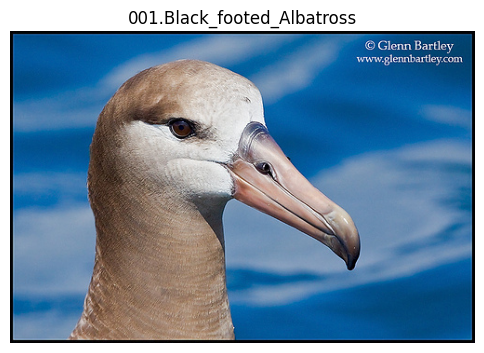

In [87]:
# Como medida de chequeo de seguimiento del proceso, abrimos una fotografía y comprobamos visualmente su correspondencia con la tabla.

from PIL import Image
import matplotlib.pyplot as plt

# 1. Seleccionar la primera fila de nuestra tabla.
# iloc permite seleccionar filas por su posición.
example = image_table.iloc[0]

# 2. Construir la ruta completa de la fotografía.
# image_path contiene la ruta relativa dentro de "images".
image_file = CUB_DIR / "images" / example["image_path"]

# 3. Comprobar que la fotografía existe.
if not image_file.is_file():
    raise FileNotFoundError(f"No se encontró: {image_file}")

# 4. Abrir la fotografía y convertirla a RGB.
# RGB representa cada píxel mediante tres canales:
# rojo, verde y azul.
with Image.open(image_file) as source:
    image = source.convert("RGB")

# 5. Mostrar los datos asociados.
print("Identificador de imagen:", example["image_id"])
print("Identificador de especie:", example["class_id"])
print("Especie:", example["class_name"])
print("Dimensiones (ancho, alto):", image.size)
print("Modo de color:", image.mode)

# 6. Visualizar la fotografía con su etiqueta.
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(example["class_name"])
plt.axis("off")
plt.show()

## LA IMAGEN SE ABRE SATISFACTORIAMENTE... SEGUIMOS AL SIGUIENTE PASO




## PARTE I - PASO COMUN - CAJA DELIMITADORA (BOUNDING BOX)

Ahora añadiremos la caja delimitadora (bounding box) a la tabla y la dibujaremos sobre esta imagen.

En el ejemplo tomado del dataset, nos indica qué región contiene al ave y posteriormente permitirá recortarla.

Esquina superior izquierda: x=60.0, y=27.0
Ancho de la caja: 325.0 píxeles
Alto de la caja: 304.0 píxeles


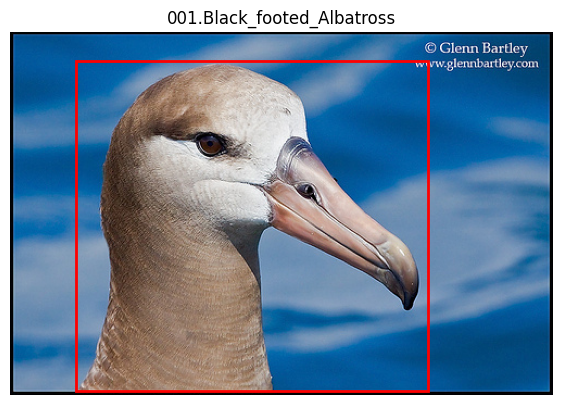

In [88]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ------------------------------------------------------------
# 1. LEER LAS CAJAS DELIMITADORAS
# ------------------------------------------------------------
# Cada fila de bounding_boxes.txt contiene:
#   image_id: identificador de la fotografía.
#   bbox_x: posición horizontal del borde izquierdo.
#   bbox_y: posición vertical del borde superior.
#   bbox_w: ancho de la caja.
#   bbox_h: alto de la caja.
#
# Las cuatro medidas geométricas están expresadas en píxeles
# respecto a la imagen original.
boxes = pd.read_csv(
    CUB_DIR / "bounding_boxes.txt",
    sep=r"\s+",
    header=None,
    names=["image_id", "bbox_x", "bbox_y", "bbox_w", "bbox_h"],
)

# ------------------------------------------------------------
# 2. INCORPORAR LAS CAJAS A LA TABLA
# ------------------------------------------------------------
# Quitamos estas columnas si ya estaban presentes, para poder
# ejecutar nuevamente la celda sin crear columnas duplicadas.
bbox_columns = ["bbox_x", "bbox_y", "bbox_w", "bbox_h"]

image_table = image_table.drop(
    columns=bbox_columns,
    errors="ignore",
)

# Unimos por el identificador de imagen.
# Conservamos todas las fotografías y exigimos una relación
# de una sola caja por fotografía.
image_table = image_table.merge(
    boxes,
    on="image_id",
    how="left",
    validate="one_to_one",
)

# ------------------------------------------------------------
# 3. VERIFICAR LAS ANOTACIONES
# ------------------------------------------------------------
# Todas las imágenes deben tener las cuatro medidas.
assert image_table[bbox_columns].notna().all().all(), (
    "Hay imágenes sin una caja delimitadora completa."
)

# El ancho y el alto deben ser positivos.
assert (image_table[["bbox_w", "bbox_h"]] > 0).all().all(), (
    "Hay cajas con ancho o alto no positivo."
)

# ------------------------------------------------------------
# 4. RECUPERAR LA CAJA DE LA IMAGEN QUE ABRIMOS
# ------------------------------------------------------------
# Buscamos por image_id para mantener la correspondencia
# con la fotografía almacenada en la variable image.
example_with_box = image_table.loc[
    image_table["image_id"] == example["image_id"]
].iloc[0]

x = example_with_box["bbox_x"]
y = example_with_box["bbox_y"]
w = example_with_box["bbox_w"]
h = example_with_box["bbox_h"]

print(f"Esquina superior izquierda: x={x}, y={y}")
print(f"Ancho de la caja: {w} píxeles")
print(f"Alto de la caja: {h} píxeles")

# ------------------------------------------------------------
# 5. DIBUJAR LA CAJA SOBRE LA FOTOGRAFÍA
# ------------------------------------------------------------
# En la imagen, x aumenta hacia la derecha e y hacia abajo.
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(image)

# Rectangle recibe la esquina superior izquierda, ancho y alto.
# fill=False permite ver el ave dentro del rectángulo.
box_patch = Rectangle(
    (x, y),
    w,
    h,
    linewidth=2,
    edgecolor="red",
    fill=False,
)

ax.add_patch(box_patch)
ax.set_title(example_with_box["class_name"])
ax.axis("off")
plt.show()

## PARTE II - PASO COMUN - AÑADIR PARTICION A LA TABLA, SIN VALIDAR TODAVIA

Ahora añadiremos a la tabla la partición oficial de cada imagen, sin crear todavía la validación

In [89]:

# ------------------------------------------------------------
# 1. LEER LA PARTICIÓN OFICIAL
# ------------------------------------------------------------
# train_test_split.txt contiene:
#   image_id: identificador de la fotografía.
#   is_train: 1 = entrenamiento oficial; 0 = prueba oficial.
#
# Respetaremos esta separación para conservar intacto
# el conjunto de prueba definido por los autores.
official_split = pd.read_csv(
    CUB_DIR / "train_test_split.txt",
    sep=r"\s+",
    header=None,
    names=["image_id", "is_train"],
)

# ------------------------------------------------------------
# 2. AÑADIR LA PARTICIÓN A LA TABLA MAESTRA
# ------------------------------------------------------------
# Eliminamos la columna si ya existe para permitir
# ejecutar nuevamente esta celda sin duplicarla.
image_table = image_table.drop(
    columns=["is_train"],
    errors="ignore",
)

# Unimos por image_id y conservamos todas las fotografías.
image_table = image_table.merge(
    official_split,
    on="image_id",
    how="left",
    validate="one_to_one",
)

# ------------------------------------------------------------
# 3. COMPROBAR LAS ASIGNACIONES
# ------------------------------------------------------------
# isin comprueba que cada imagen tenga uno de los dos valores
# permitidos. También detecta valores faltantes.
assert image_table["is_train"].isin([0, 1]).all(), (
    "Hay imágenes con una partición faltante o inválida."
)

# Contamos las imágenes de cada conjunto oficial.
n_train = int((image_table["is_train"] == 1).sum())
n_test = int((image_table["is_train"] == 0).sum())

# Verificamos los tamaños esperados.
assert n_train == 5_994, "El entrenamiento oficial debe tener 5.994 imágenes."
assert n_test == 5_794, "La prueba oficial debe tener 5.794 imágenes."

# ------------------------------------------------------------
# 4. MOSTRAR EL RESULTADO
# ------------------------------------------------------------
print(f"Entrenamiento oficial: {n_train:,} imágenes")
print(f"Prueba oficial: {n_test:,} imágenes")

display(
    image_table[
        ["image_id", "class_name", "is_train"]
    ].head()
)

Entrenamiento oficial: 5,994 imágenes
Prueba oficial: 5,794 imágenes


,image_id,class_name,is_train
0,1,001.Black_footed_Albatross,0
1,2,001.Black_footed_Albatross,1
2,3,001.Black_footed_Albatross,0
3,4,001.Black_footed_Albatross,1
4,5,001.Black_footed_Albatross,1


## PARTE III - COMUN - DIVISIÓN DEL DATASET DE ACUERDO A PARAMETROS ENTRENAMIENTO, VALIDACION Y TEST

Ahora dividiremos el entrenamiento oficial en entrenamiento y validación, conservando las proporciones por especie, de acuerdo a los criterios propuestos en el taller.

In [90]:

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. SEPARAR LOS DOS CONJUNTOS OFICIALES
# ------------------------------------------------------------
# copy crea tablas independientes para trabajar con ellas.
official_train = image_table.loc[
    image_table["is_train"] == 1
].copy()

test_table = image_table.loc[
    image_table["is_train"] == 0
].copy()


# ------------------------------------------------------------
# 2. DIVIDIR EL ENTRENAMIENTO OFICIAL
# ------------------------------------------------------------
# Reservamos 600 imágenes para validación, aproximadamente
# el 10 % de las 5.994 imágenes del entrenamiento oficial.
#
# stratify conserva aproximadamente la proporción de especies.
# random_state fija la semilla para reproducir esta división.
train_table, val_table = train_test_split(
    official_train,
    test_size=600,
    stratify=official_train["class_id"],
    random_state=42,
)


# ------------------------------------------------------------
# 3. IDENTIFICAR CADA PARTICIÓN
# ------------------------------------------------------------
# La columna split registra el uso asignado a cada imagen.
train_table = train_table.copy()
val_table = val_table.copy()

train_table["split"] = "train"
val_table["split"] = "val"
test_table["split"] = "test"


# ------------------------------------------------------------
# 4. VERIFICAR QUE NO HAYA IMÁGENES COMPARTIDAS
# ------------------------------------------------------------
# Los conjuntos de identificadores permiten detectar
# si una fotografía aparece en más de una partición.
train_ids = set(train_table["image_id"])
val_ids = set(val_table["image_id"])
test_ids = set(test_table["image_id"])

assert train_ids.isdisjoint(val_ids), "Hay imágenes compartidas entre train y val."
assert train_ids.isdisjoint(test_ids), "Hay imágenes compartidas entre train y test."
assert val_ids.isdisjoint(test_ids), "Hay imágenes compartidas entre val y test."

# También comprobamos que no se haya perdido ninguna imagen.
assert train_ids | val_ids | test_ids == set(image_table["image_id"]), (
    "Las particiones no contienen todas las imágenes."
)


# ------------------------------------------------------------
# 5. INCORPORAR LAS ASIGNACIONES A LA TABLA MAESTRA
# ------------------------------------------------------------
# Conservamos las demás columnas y añadimos el split final.
split_assignments = pd.concat(
    [
        train_table[["image_id", "split"]],
        val_table[["image_id", "split"]],
        test_table[["image_id", "split"]],
    ],
    ignore_index=True,
)

image_table = image_table.drop(
    columns=["split"],
    errors="ignore",
).merge(
    split_assignments,
    on="image_id",
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# 6. COMPROBAR TAMAÑOS Y REPRESENTACIÓN DE ESPECIES
# ------------------------------------------------------------
summary = (
    image_table.groupby("split")
    .agg(
        imagenes=("image_id", "size"),
        especies=("class_id", "nunique"),
    )
    .reindex(["train", "val", "test"])
)

assert summary["imagenes"].tolist() == [5_394, 600, 5_794]
assert (summary["especies"] == 200).all()

display(summary)

,imagenes,especies
split,,
train,5394,200
val,600,200
test,5794,200


## PARTE IV - COMUN - LECTURA DE LOS 312 ATRIBUTOS POR IMAGEN

Leemos las anotaciones de los 312 atributos visuales por imagen:

1 indica presencia y 0 indica ausencia del atributo. Después, las reorganizamos en una fila por imagen y una columna por atributo.

Los atributos binarios se conservarán sin escalar,como indica el taller. Más adelante añadiremos seis variables geométricas para completar las 318 características tabulares.

Las tablas **train_table**, **val_table** y **test_table** creadas antes todavía no contienen estas nuevas columnas. Al terminar de integrar las modalidades, las reconstruiremos desde image_table, conservando las particiones ya asignadas.

In [91]:


# ------------------------------------------------------------
# 1. LEER LOS TRES CAMPOS NECESARIOS
# ------------------------------------------------------------
# Algunas filas contienen campos adicionales.
# Seleccionamos explícitamente las tres primeras columnas:
#   columna 0: image_id
#   columna 1: attribute_id
#   columna 2: is_present
#
# No omitimos filas ni utilizamos los campos adicionales.
attributes_long = pd.read_csv(
    CUB_DIR / "attributes" / "image_attribute_labels.txt",
    sep=r"\s+",
    header=None,
    usecols=[0, 1, 2],
    names=["image_id", "attribute_id", "is_present"],
    dtype={
        "image_id": "int64",
        "attribute_id": "int64",
        "is_present": "int64",
    },
)

# ------------------------------------------------------------
# 2. COMPROBAR EL NÚMERO DE ANOTACIONES
# ------------------------------------------------------------
# Esperamos 312 anotaciones por cada una de las 11.788 imágenes.
expected_rows = 11_788 * 312

assert len(attributes_long) == expected_rows, (
    f"Se esperaban {expected_rows:,} anotaciones, "
    f"pero se leyeron {len(attributes_long):,}."
)

print(f"Anotaciones leídas: {len(attributes_long):,}")
display(attributes_long.head())


# ------------------------------------------------------------
# 3. CONVERTIR LAS ANOTACIONES EN UNA TABLA POR IMAGEN
# ------------------------------------------------------------
# pivot reorganiza la tabla:
#   antes: una fila por imagen y atributo;
#   después: una fila por imagen y 312 columnas de atributos.
attributes_wide = attributes_long.pivot(
    index="image_id",
    columns="attribute_id",
    values="is_present",
).sort_index(axis=1)

# Cada imagen debe tener sus 312 anotaciones completas.
assert attributes_wide.shape == (11_788, 312)
assert attributes_wide.notna().all().all(), (
    "Hay imágenes con atributos faltantes."
)

# Asignamos nombres estables, conservando el orden de los IDs.
attributes_wide.columns = [
    f"attr_{attribute_id:03d}"
    for attribute_id in attributes_wide.columns
]

# Los valores binarios pueden guardarse como enteros de 8 bits.
attributes_wide = attributes_wide.astype("uint8")

# Convertimos image_id de índice a columna para poder unirlo.
attributes_wide = attributes_wide.reset_index()

# ------------------------------------------------------------
# 4. INCORPORAR LOS ATRIBUTOS A LA TABLA MAESTRA
# ------------------------------------------------------------
attribute_columns = [
    f"attr_{attribute_id:03d}"
    for attribute_id in range(1, 313)
]

# Permitimos volver a ejecutar la celda sin duplicar columnas.
image_table = image_table.drop(
    columns=attribute_columns,
    errors="ignore",
).merge(
    attributes_wide,
    on="image_id",
    how="left",
    validate="one_to_one",
)

# ------------------------------------------------------------
# 5. INSPECCIONAR EL RESULTADO
# ------------------------------------------------------------
print("Imágenes:", len(image_table))
print("Atributos binarios por imagen:", len(attribute_columns))

# Mostramos solo cinco atributos para facilitar la lectura.
display(
    image_table[
        ["image_id", "split"] + attribute_columns[:5]
    ].head()
)

Anotaciones leídas: 3,677,856


,image_id,attribute_id,is_present
0,1,1,0
1,1,2,0
2,1,3,0
3,1,4,0
4,1,5,1


Imágenes: 11788
Atributos binarios por imagen: 312


,image_id,split,attr_001,attr_002,attr_003,attr_004,attr_005
0,1,test,0,0,0,0,1
1,2,train,0,0,0,0,0
2,3,test,0,0,0,0,1
3,4,val,0,0,0,0,1
4,5,val,0,0,0,0,1


## PARTE V - COMUN - DETERMINAR CARACTERISTICAS DE IMAGENES: ALTO Y ANCHO

Registraremos el ancho y el alto originales de cada fotografía, todavía como parte del procedimiento común para ambos casos (pytorch y keras). Esas dimensiones permitirán expresar la caja delimitadora en proporción al tamaño de la imagen.

Creamos dos columnas auxiliares para Estas dos columnas son medidas auxiliares,
no dos características adicionales del vector final. Las utilizaremos para calcular las seis variables geométricas que, junto con los 312 atributos, formarán las 318 características tabulares.

In [92]:

from PIL import Image
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PREPARAR EL REGISTRO DE DIMENSIONES
# ------------------------------------------------------------
# Guardaremos un registro por imagen con:
#   image_id: identificador de la fotografía.
#   image_width: ancho original, en píxeles.
#   image_height: alto original, en píxeles.
dimension_records = []


# ------------------------------------------------------------
# 2. CONSULTAR EL TAMAÑO DE CADA FOTOGRAFÍA
# ------------------------------------------------------------
# itertuples recorre las filas de la tabla.
# tqdm muestra una barra de progreso.
for row in tqdm(
    image_table[["image_id", "image_path"]].itertuples(index=False),
    total=len(image_table),
    desc="Leyendo dimensiones",
):
    # Construimos la ruta completa de la fotografía.
    image_file = CUB_DIR / "images" / row.image_path

    # Pillow consulta el tamaño sin convertir la imagen
    # en un arreglo de píxeles ni modificar el archivo.
    # El bloque with cierra el archivo al terminar la consulta.
    with Image.open(image_file) as img:
        width, height = img.size

    # Vinculamos las dimensiones con el identificador de imagen.
    dimension_records.append(
        {
            "image_id": row.image_id,
            "image_width": width,
            "image_height": height,
        }
    )


# ------------------------------------------------------------
# 3. CONVERTIR LOS REGISTROS EN UNA TABLA
# ------------------------------------------------------------
dimensions = pd.DataFrame(dimension_records)

# Todas las dimensiones deben ser positivas.
assert (dimensions[["image_width", "image_height"]] > 0).all().all(), (
    "Hay imágenes con dimensiones no válidas."
)


# ------------------------------------------------------------
# 4. AÑADIR LAS DIMENSIONES A LA TABLA MAESTRA
# ------------------------------------------------------------
# Eliminamos estas columnas si existen para permitir
# volver a ejecutar la celda sin duplicarlas.
image_table = image_table.drop(
    columns=["image_width", "image_height"],
    errors="ignore",
).merge(
    dimensions,
    on="image_id",
    how="left",
    validate="one_to_one",
)

# Comprobamos que todas las imágenes tengan sus dimensiones.
assert image_table[
    ["image_width", "image_height"]
].notna().all().all(), "Faltan dimensiones en algunas imágenes."


# ------------------------------------------------------------
# 5. INSPECCIONAR EL RESULTADO
# ------------------------------------------------------------
print(f"Imágenes con dimensiones registradas: {len(dimensions):,}")

display(
    image_table[
        ["image_id", "image_width", "image_height"]
    ].head()
)

Leyendo dimensiones:   0%|          | 0/11788 [00:00<?, ?it/s]

Imágenes con dimensiones registradas: 11,788


,image_id,image_width,image_height
0,1,500,335
1,2,500,336
2,3,500,347
3,4,415,500
4,5,331,380


## PARTE VI - COMUN - SEIS (6) VARIABLES GEOMÉTRICAS

Ya tenemos las dimensiones de las 11.788 fotografías. Ahora podemos calcular las seis variables geométricas. Seguimos en la preparación común.

Como el enunciado menciona posición, tamaño, aspecto y área sin especificar las fórmulas, adoptaremos y documentaremos estas definiciones:

- Variable	Cálculo	Significado
- bbox_x_rel	\(x/W\)	Posición horizontal relativa
- bbox_y_rel	\(y/H\)	Posición vertical relativa
- bbox_w_rel	\(w/W\)	Ancho relativo
- bbox_h_rel	\(h/H\)	Alto relativo
- bbox_aspect	\(w/h\)	Relación de aspecto de la caja
- bbox_area_rel	\(wh/(WH)\)	Proporción de imagen ocupada por la caja


Aquí, \(W,H\) son las dimensiones de la fotografía y \(x,y,w,h\), las de su caja original, sin margen.

In [93]:
import numpy as np

# ------------------------------------------------------------
# 1. RECUPERAR LAS MEDIDAS NECESARIAS
# ------------------------------------------------------------
# Cada variable contiene una columna completa de la tabla.
W = image_table["image_width"]
H = image_table["image_height"]

x = image_table["bbox_x"]
y = image_table["bbox_y"]
w = image_table["bbox_w"]
h = image_table["bbox_h"]


# ------------------------------------------------------------
# 2. CALCULAR POSICIÓN Y TAMAÑO RELATIVOS
# ------------------------------------------------------------
# Dividimos las medidas horizontales por el ancho de la imagen
# y las verticales por su alto.
#
# Esto permite comparar fotografías de distintos tamaños.
image_table["bbox_x_rel"] = x / W
image_table["bbox_y_rel"] = y / H
image_table["bbox_w_rel"] = w / W
image_table["bbox_h_rel"] = h / H


# ------------------------------------------------------------
# 3. CALCULAR LA RELACIÓN DE ASPECTO
# ------------------------------------------------------------
# Un valor mayor que 1 indica una caja más ancha que alta.
# Un valor menor que 1 indica una caja más alta que ancha.
image_table["bbox_aspect"] = w / h


# ------------------------------------------------------------
# 4. CALCULAR EL ÁREA RELATIVA
# ------------------------------------------------------------
# Comparamos el área de la caja con el área de la fotografía.
# Por ejemplo, 0.50 significa que la caja ocupa el 50 %
# del área total; no significa que todos esos píxeles sean ave.
image_table["bbox_area_rel"] = (w * h) / (W * H)


# ------------------------------------------------------------
# 5. REGISTRAR EL ORDEN DE LAS SEIS VARIABLES
# ------------------------------------------------------------
# Utilizaremos este mismo orden en ambos frameworks.
geometry_columns = [
    "bbox_x_rel",
    "bbox_y_rel",
    "bbox_w_rel",
    "bbox_h_rel",
    "bbox_aspect",
    "bbox_area_rel",
]


# ------------------------------------------------------------
# 6. VERIFICAR LOS RESULTADOS
# ------------------------------------------------------------
# No debe haber valores faltantes ni infinitos.
geometry_values = image_table[geometry_columns].to_numpy()

assert np.isfinite(geometry_values).all(), (
    "Hay valores faltantes o infinitos en las variables geométricas."
)

# El tamaño, la relación de aspecto y el área deben ser positivos.
assert (
    image_table[
        ["bbox_w_rel", "bbox_h_rel", "bbox_aspect", "bbox_area_rel"]
    ] > 0
).all().all(), "Hay medidas geométricas no positivas."


# ------------------------------------------------------------
# 7. INSPECCIONAR LAS PRIMERAS IMÁGENES
# ------------------------------------------------------------
display(
    image_table[
        ["image_id"] + geometry_columns
    ].head().round(4)
)

,image_id,bbox_x_rel,bbox_y_rel,bbox_w_rel,bbox_h_rel,bbox_aspect,bbox_area_rel
0,1,0.1200,0.0806,0.6500,0.9075,1.0691,0.5899
1,2,0.2780,0.0893,0.3060,0.7857,0.5795,0.2404
2,3,0.0280,0.3228,0.7760,0.5360,2.0860,0.4160
3,4,0.2699,0.1800,0.6145,0.4840,1.0537,0.2974
4,5,0.2115,0.1316,0.4048,0.7974,0.4422,0.3228


Todavía no hemos estandarizado estas seis variables. En el siguiente paso ajustaremos StandardScaler únicamente con las filas de entrenamiento y aplicaremos esa misma transformación a validación y prueba.

Los valores son coherentes. Por ejemplo, en la primera imagen la caja ocupa aproximadamente el 59 % del área de la fotografía (bbox_area_rel = 0.5899).

Seguimos en la preparación común. Ahora estandarizaremos las seis variables geométricas.

La media y la desviación estándar se calcularán solo con entrenamiento. Mantendremos las columnas originales y añadiremos otras con sufijo _scaled.

## PARTE VII - COMUN - STANDARIZACIÓN DE LAS SEIS (6) VARIABLES GEOMETRICAS

Realizamos proceso de estandarización (stadarization) para los valores de las variables geométricas de acuerdo a los principios propuestos. El resultado final deberá situar la media en 0 y la Desv. Std en 1.

In [94]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# ------------------------------------------------------------
# 1. IDENTIFICAR LAS FILAS DE ENTRENAMIENTO
# ------------------------------------------------------------
# Esta máscara contiene True únicamente para las imágenes
# asignadas a entrenamiento.
train_mask = image_table["split"].eq("train")

assert train_mask.sum() == 5_394, (
    "Se esperaban 5.394 imágenes de entrenamiento."
)


# ------------------------------------------------------------
# 2. AJUSTAR EL ESCALADOR SOLO CON ENTRENAMIENTO
# ------------------------------------------------------------
# fit calcula una media y una desviación estándar
# para cada una de las seis variables geométricas.
geometry_scaler = StandardScaler()

geometry_scaler.fit(
    image_table.loc[train_mask, geometry_columns]
)


# ------------------------------------------------------------
# 3. TRANSFORMAR TODAS LAS PARTICIONES
# ------------------------------------------------------------
# transform reutiliza las estadísticas de entrenamiento.
# No calcula nuevas estadísticas con validación ni prueba.
scaled_geometry = geometry_scaler.transform(
    image_table[geometry_columns]
).astype(np.float32)


# ------------------------------------------------------------
# 4. GUARDAR LOS VALORES ESTANDARIZADOS
# ------------------------------------------------------------
# Conservamos las medidas originales para poder interpretarlas.
geometry_scaled_columns = [
    f"{column}_scaled"
    for column in geometry_columns
]

image_table[geometry_scaled_columns] = scaled_geometry

# Verificamos que no haya valores faltantes ni infinitos.
assert np.isfinite(scaled_geometry).all(), (
    "Hay valores no válidos después de estandarizar."
)


# ------------------------------------------------------------
# 5. DEFINIR LAS 318 CARACTERÍSTICAS TABULARES
# ------------------------------------------------------------
# Incluimos los 312 atributos binarios sin modificar
# y las seis variables geométricas estandarizadas.
#
# No incluimos las medidas geométricas originales,
# los identificadores ni la etiqueta de especie.
tabular_columns = attribute_columns + geometry_scaled_columns

assert len(tabular_columns) == 318


# ------------------------------------------------------------
# 6. COMPROBAR LA ESTANDARIZACIÓN EN ENTRENAMIENTO
# ------------------------------------------------------------
# En train, las medias deben ser aproximadamente 0
# y las desviaciones estándar aproximadamente 1.
#
# ddof=0 utiliza la misma definición de desviación estándar
# que StandardScaler.
train_scaled = image_table.loc[
    train_mask, geometry_scaled_columns
]

scaling_summary = pd.DataFrame({
    "media_train": train_scaled.mean(),
    "desviacion_train": train_scaled.std(ddof=0),
})

display(scaling_summary.round(4))

print("Características tabulares por imagen:", len(tabular_columns))

,media_train,desviacion_train
bbox_x_rel_scaled,0.0,1.0
bbox_y_rel_scaled,-0.0,1.0
bbox_w_rel_scaled,-0.0,1.0
bbox_h_rel_scaled,-0.0,1.0
bbox_aspect_scaled,0.0,1.0
bbox_area_rel_scaled,0.0,1.0


Características tabulares por imagen: 318


La estandarización quedó tal como esperábamos: las seis variables presentan ahora una media aproximadamente 0 y desviación estándar 1 en entrenamiento. El valor -0.0 es un efecto del redondeo numérico.

Ya tenemos entonces las 318 características tabulares por imagen:
- 312 atributos binarios sin escalar.
- 6 variables geométricas estandarizadas con estadísticas de entrenamiento.

Seguimos ahora con los pasosde preparación de datos común. En el siguiente apartado, incorporaremos el texto: las diez descripcreiones por fotografía del trabajo de Reed (2016).

## PARTE VIII - COMUN - INCORPORACION DE TEXTO SEGÚN TRABAJO DE REED (2016)

In [95]:
from pathlib import Path
import zipfile

# ------------------------------------------------------------
# 1. EXTRAER LOS ARCHIVOS DE DESCRIPCIONES
# ------------------------------------------------------------
# caption_entries contiene las rutas de los archivos .txt
# identificados dentro del ZIP interno.
with zipfile.ZipFile(inner_zip_path) as text_archive:
    for name in caption_entries:
        text_archive.extract(name, path=DATA_DIR)

# Las rutas del ZIP comienzan con "text/".
CAPTIONS_DIR = DATA_DIR / "text"


# ------------------------------------------------------------
# 2. CONSTRUIR LA RUTA DE TEXTO PARA CADA IMAGEN
# ------------------------------------------------------------
# Imagen:
#   001.Black_footed_Albatross/nombre.jpg
# Texto:
#   001.Black_footed_Albatross/nombre.txt
#
# Conservamos la carpeta y el nombre, cambiando la extensión.
image_table["caption_path"] = image_table["image_path"].map(
    lambda relative_path: str(
        CAPTIONS_DIR / Path(relative_path).with_suffix(".txt")
    )
)


# ------------------------------------------------------------
# 3. VERIFICAR QUE CADA IMAGEN TENGA SU ARCHIVO DE TEXTO
# ------------------------------------------------------------
# El número total de archivos no basta: también deben coincidir
# sus nombres con los de nuestras fotografías.
missing_captions = [
    path
    for path in image_table["caption_path"]
    if not Path(path).is_file()
]

if missing_captions:
    raise FileNotFoundError(
        f"Faltan {len(missing_captions)} archivos de descripciones. "
        f"Ejemplos: {missing_captions[:3]}"
    )


# ------------------------------------------------------------
# 4. LEER LAS DESCRIPCIONES DE CADA FOTOGRAFÍA
# ------------------------------------------------------------
def read_captions(path):
    # Leemos el texto original, sin tokenizarlo todavía.
    text = Path(path).read_text(encoding="utf-8")

    # Cada línea contiene una descripción.
    # Quitamos espacios exteriores y descartamos líneas vacías.
    return [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]


# Cada celda de esta columna contendrá una lista de descripciones.
image_table["captions"] = image_table["caption_path"].map(read_captions)

# Registramos cuántas descripciones tiene cada imagen.
image_table["n_captions"] = image_table["captions"].map(len)


# ------------------------------------------------------------
# 5. COMPROBAR LAS DIEZ DESCRIPCIONES POR IMAGEN
# ------------------------------------------------------------
# Si hay diferencias, mostramos las imágenes afectadas
# y detenemos el proceso para revisarlas.
unexpected_counts = image_table.loc[
    image_table["n_captions"] != 10,
    ["image_id", "caption_path", "n_captions"],
]

if not unexpected_counts.empty:
    display(unexpected_counts.head(10))
    raise ValueError(
        f"{len(unexpected_counts)} imágenes no tienen "
        "exactamente diez descripciones no vacías."
    )

print(f"Imágenes con texto: {len(image_table):,}")
print(f"Descripciones totales: {image_table['n_captions'].sum():,}")


# ------------------------------------------------------------
# 6. INSPECCIONAR LAS DESCRIPCIONES DE UNA IMAGEN
# ------------------------------------------------------------
example_text = image_table.iloc[0]

print("\nImagen:", example_text["image_path"])
print("Especie:", example_text["class_name"])
print("Partición:", example_text["split"])

for number, caption in enumerate(example_text["captions"], start=1):
    print(f"{number}. {caption}")

Imágenes con texto: 11,788
Descripciones totales: 117,880

Imagen: 001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg
Especie: 001.Black_footed_Albatross
Partición: test
1. light tan colored bird with a white head and an orange beak.
2. the bird has a very thick, curved, and beige beak
3. this bird has a long neck that is grainy and a pastel orange/blue narrow beak that droops down at the tip
4. this bird is light brown, has a long hooked bill, and looks dumb.
5. this large white bird has a large curved bill and a brown eye
6. this bird is white with grey and has a long, pointy beak.
7. this bird is white with grey and has a long, pointy beak.
8. the crown of the bird is white, with light brown tones throughout.
9. the crown of the bird has distinctive tones of white and brown throughout.
10. this bird has a long neck and an orange bill


La integración del texto está completa: las 11.788 imágenes tienen diez descripciones cada una.

El ejemplo también muestra características reales del corpus: hay frases duplicadas y expresiones subjetivas como “looks dumb”. Las conservaremos, ya que, aunque se trate de expresiones poco objetivas y no perzcionalizadas, forman parte del dataset originla que motiva este ejercicio. Para no seguir inspeccionando todo el contenido de prueba, utilizaremos un ejemplo de entrenamiento desde ahora.

## PASO IX - COMUN - TOKENIZACION. SEGUN CRITERIO TALLER: "Minúsculas, solo palabras (sin puntuación ni números)"

In [96]:
import re

# ------------------------------------------------------------
# 1. DEFINIR LA LIMPIEZA Y TOKENIZACIÓN
# ------------------------------------------------------------
# Un token será, en este taller, una secuencia de letras.
# Convertimos el texto a minúsculas y extraemos palabras.
#
# La puntuación, los números y símbolos quedan fuera.
# Por ejemplo: "Orange/blue beak." → ["orange", "blue", "beak"]
def tokenize_caption(text):
    return re.findall(r"[a-z]+", text.lower())


# ------------------------------------------------------------
# 2. PROCESAR LAS DIEZ DESCRIPCIONES DE CADA IMAGEN
# ------------------------------------------------------------
# Cada imagen conservará una lista de diez listas de palabras.
# No modificamos la columna captions: mantiene el texto original.
image_table["caption_tokens"] = image_table["captions"].map(
    lambda captions: [
        tokenize_caption(caption)
        for caption in captions
    ]
)


# ------------------------------------------------------------
# 3. COMPROBAR QUE SE CONSERVARON LAS DESCRIPCIONES
# ------------------------------------------------------------
assert image_table["caption_tokens"].map(len).eq(10).all(), (
    "Alguna imagen no conserva sus diez descripciones."
)

# Contamos las descripciones que quedaron sin palabras.
# Más adelante definiremos cómo codificarlas con longitud mínima 1.
empty_count = sum(
    len(tokens) == 0
    for captions in image_table["caption_tokens"]
    for tokens in captions
)

print("Descripciones sin palabras después de limpiar:", empty_count)


# ------------------------------------------------------------
# 4. INSPECCIONAR UN EJEMPLO DE ENTRENAMIENTO
# ------------------------------------------------------------
train_example = image_table.loc[
    image_table["split"] == "train"
].iloc[0]

print("\nDescripción original:")
print(train_example["captions"][0])

print("\nPalabras extraídas:")
print(train_example["caption_tokens"][0])

Descripciones sin palabras después de limpiar: 0

Descripción original:
the wings are brown, long and narrow, and have white markings on the secondaries, the bill is blunt tipped and black, the head is light brown with a white thin marking between the eye and the beak.

Palabras extraídas:
['the', 'wings', 'are', 'brown', 'long', 'and', 'narrow', 'and', 'have', 'white', 'markings', 'on', 'the', 'secondaries', 'the', 'bill', 'is', 'blunt', 'tipped', 'and', 'black', 'the', 'head', 'is', 'light', 'brown', 'with', 'a', 'white', 'thin', 'marking', 'between', 'the', 'eye', 'and', 'the', 'beak']


## PARTE X - COMUN - CONSTRUCCION DE VOCABULARIO

Ahora construiremos el vocabulario y calcularemos la longitud máxima, utilizando únicamente las descripciones de entrenamiento. Seguimos en la preparación común del dataset para los dos métodos solicitados.

Todavía no convertimos las frases en IDs. Primero dejamos definidos el vocabulario y max_len; ambos se reutilizarán sin reajustarlos en validación y prueba.

In [97]:
from collections import Counter
import numpy as np

# ------------------------------------------------------------
# 1. SELECCIONAR LOS TEXTOS DE ENTRENAMIENTO
# ------------------------------------------------------------
# Utilizamos image_table, que ya contiene todas las columnas.
# Cada imagen tiene diez listas de palabras.
train_token_lists = [
    tokens
    for captions in image_table.loc[
        image_table["split"] == "train", "caption_tokens"
    ]
    for tokens in captions
]

assert len(train_token_lists) == 5_394 * 10

print("Descripciones de entrenamiento:", len(train_token_lists))


# ------------------------------------------------------------
# 2. CONTAR LA FRECUENCIA DE CADA PALABRA
# ------------------------------------------------------------
# Counter cuenta las apariciones totales de cada palabra
# en las diez descripciones de cada imagen de entrenamiento.
word_counts = Counter(
    word
    for tokens in train_token_lists
    for word in tokens
)


# ------------------------------------------------------------
# 3. CONSTRUIR EL VOCABULARIO
# ------------------------------------------------------------
# El taller exige:
#   <pad> = 0: relleno de secuencias cortas.
#   <unk> = 1: palabra que no está en el vocabulario.
#
# Incluimos solo palabras con al menos dos apariciones.
# Las ordenamos alfabéticamente para asignar IDs reproducibles.
vocab = {
    "<pad>": 0,
    "<unk>": 1,
}

retained_words = sorted(
    word
    for word, count in word_counts.items()
    if count >= 2
)

vocab.update({
    word: index
    for index, word in enumerate(retained_words, start=2)
})

# Creamos también la correspondencia inversa.
# Nos permitirá interpretar los IDs más adelante.
id_to_word = {
    index: word
    for word, index in vocab.items()
}

print("Palabras distintas antes del filtro:", len(word_counts))
print("Tamaño del vocabulario, incluidos pad y unk:", len(vocab))


# ------------------------------------------------------------
# 4. CALCULAR LA LONGITUD MÁXIMA
# ------------------------------------------------------------
# Medimos las longitudes antes de truncar o añadir relleno.
train_lengths = np.array(
    [len(tokens) for tokens in train_token_lists],
    dtype=np.int64,
)

# El taller solicita el percentil 95 de entrenamiento.
# Redondeamos hacia arriba para obtener un número entero.
# Garantizamos además una longitud máxima mínima de 1.
max_len = max(
    1,
    int(np.ceil(np.percentile(train_lengths, 95))),
)

print("Longitud mínima observada:", train_lengths.min())
print("Longitud máxima observada:", train_lengths.max())
print("Longitud máxima elegida (max_len):", max_len)


# ------------------------------------------------------------
# 5. MEDIR CUÁNTAS DESCRIPCIONES SE TRUNCARÍAN
# ------------------------------------------------------------
# Todavía no truncamos: solo comprobamos el efecto del límite.
n_truncated = int((train_lengths > max_len).sum())

print(
    f"Descripciones de entrenamiento que se truncarían: "
    f"{n_truncated:,} ({n_truncated / len(train_lengths):.2%})"
)


# ------------------------------------------------------------
# 6. INSPECCIONAR LOS PRIMEROS IDENTIFICADORES
# ------------------------------------------------------------
print("\nPrimeras entradas del vocabulario:")

for word, index in list(vocab.items())[:12]:
    print(f"{word!r}: {index}")

Descripciones de entrenamiento: 53940
Palabras distintas antes del filtro: 3836
Tamaño del vocabulario, incluidos pad y unk: 2079
Longitud mínima observada: 1
Longitud máxima observada: 66
Longitud máxima elegida (max_len): 25
Descripciones de entrenamiento que se truncarían: 2,185 (4.05%)

Primeras entradas del vocabulario:
'<pad>': 0
'<unk>': 1
'a': 2
'aa': 3
'abdomen': 4
'abdoment': 5
'abdominal': 6
'able': 7
'abnormally': 8
'about': 9
'above': 10
'abrown': 11


El vocabulario quedó definido con 2.079 identificadores y max_len = 25. Ese límite permite truncar el 4,05 % de las descripciones de entrenamiento, valor cercano al 5% solicitado. Este valor se obtuvo teniendo en cuenta que las longitudes son enteras y muchas frases tienen la misma longitud.

Palabras como "abdoment" permanecen porque aparecen al menos dos veces, pero claramente son errores. No se realiza en esta primera versión del taller ninguna corrección, ya que el taller no solicita corregir ortografía explícitamente.

## PARTE XI - COMUN -  CONVERSIÓN DE DESCRIPCIONES EN ID POR TRUNCAMIENTO Y RELLENO

In [98]:
# ------------------------------------------------------------
# 1. DEFINIR LA CODIFICACIÓN DE UNA DESCRIPCIÓN
# ------------------------------------------------------------
def encode_caption(tokens):
    # Convertimos palabras a IDs.
    # Las palabras fuera del vocabulario reciben <unk> = 1.
    token_ids = [
        vocab.get(word, vocab["<unk>"])
        for word in tokens
    ]

    # Si una descripción quedara vacía, utilizamos un <unk>.
    # Así garantizamos la longitud mínima de 1 exigida.
    if not token_ids:
        token_ids = [vocab["<unk>"]]

    # Conservamos como máximo las primeras max_len palabras.
    token_ids = token_ids[:max_len]

    # Registramos la longitud válida DESPUÉS de truncar
    # y ANTES de añadir el relleno.
    length = len(token_ids)

    # Añadimos <pad> = 0 al final hasta alcanzar max_len.
    padded_ids = token_ids + [
        vocab["<pad>"]
    ] * (max_len - length)

    return padded_ids, length


# ------------------------------------------------------------
# 2. CODIFICAR LAS DIEZ DESCRIPCIONES DE CADA IMAGEN
# ------------------------------------------------------------
# Cada imagen tendrá:
#   caption_ids: arreglo de forma (10, max_len).
#   caption_lengths: arreglo de forma (10,).
#
# Conservamos todas las alternativas. La selección de una
# descripción por lectura se realizará en cada pipeline.
encoded_captions = [
    [encode_caption(tokens) for tokens in captions]
    for captions in image_table["caption_tokens"]
]

image_table["caption_ids"] = [
    np.asarray(
        [ids for ids, length in captions],
        dtype=np.int64,
    )
    for captions in encoded_captions
]

image_table["caption_lengths"] = [
    np.asarray(
        [length for ids, length in captions],
        dtype=np.int64,
    )
    for captions in encoded_captions
]

# Eliminamos la lista auxiliar; los resultados están en la tabla.
del encoded_captions


# ------------------------------------------------------------
# 3. VERIFICAR FORMAS, LONGITUDES Y RELLENO
# ------------------------------------------------------------
for ids, lengths in zip(
    image_table["caption_ids"],
    image_table["caption_lengths"],
):
    assert ids.shape == (10, max_len)
    assert lengths.shape == (10,)
    assert ((lengths >= 1) & (lengths <= max_len)).all()
    assert ((ids >= 0) & (ids < len(vocab))).all()

    # Antes de la longitud válida no debe haber padding;
    # después, todos los valores deben ser padding.
    for sequence, length in zip(ids, lengths):
        assert (sequence[:length] != vocab["<pad>"]).all()
        assert (sequence[length:] == vocab["<pad>"]).all()


# ------------------------------------------------------------
# 4. INSPECCIONAR UNA DESCRIPCIÓN DE ENTRENAMIENTO
# ------------------------------------------------------------
example = image_table.loc[
    image_table["split"] == "train"
].iloc[0]

example_ids = example["caption_ids"][0]
example_length = int(example["caption_lengths"][0])

print("Texto original:")
print(example["captions"][0])

print("\nIDs con relleno:")
print(example_ids)

print("\nLongitud válida:", example_length)

# Reconstruimos las palabras codificadas para verificar
# qué conservó el truncamiento y dónde aparece <unk>.
print("\nTexto representado por los IDs:")
print(
    " ".join(
        id_to_word[int(index)]
        for index in example_ids[:example_length]
    )
)

print("\nCodificación verificada para todas las imágenes.")

Texto original:
the wings are brown, long and narrow, and have white markings on the secondaries, the bill is blunt tipped and black, the head is light brown with a white thin marking between the eye and the beak.

IDs con relleno:
[1808 2033   78  280 1025   56 1144   56  863 2004 1066 1191 1808 1495
 1808  193  960  236 1852   56  207 1808  868  960 1008]

Longitud válida: 25

Texto representado por los IDs:
the wings are brown long and narrow and have white markings on the secondaries the bill is blunt tipped and black the head is light

Codificación verificada para todas las imágenes.


En este paso convertimos las palabras de cada descripción en identificadores numéricos (IDs), utilizando el vocabulario construido con los datos de entrenamiento. Estos identificadores permiten representar el texto mediante arreglos que posteriormente podrán procesarse en una red neuronal.

Cada descripción se limita a 25 palabras: las secuencias más largas se truncan y las más cortas se completan con el identificador de relleno ( < pad > = 0). También conservamos la longitud válida de cada secuencia, sin contar el relleno.

Así, cada imagen queda asociada con un arreglo de forma (10, 25): diez descripciones, cada una con 25 posiciones. Posteriormente, cada lectura seleccionará una sola descripción: al azar durante el entrenamiento y siempre la primera en validación y prueba.

## PARTE XII - PREPARACION DE ETIQUETAS DE ESPECIA Y RECONTRUCCION DE TABLAS POR CADA PARTICION

In [99]:
# ------------------------------------------------------------
# 1. CONVERTIR LAS ETIQUETAS AL RANGO 0...199
# ------------------------------------------------------------
# Los identificadores originales van de 1 a 200.
# El taller solicita etiquetas enteras de 0 a 199.
#
# Conservamos class_id y creamos una columna nueva, label.
# Este cambio solo modifica la numeración, no la especie.
image_table["label"] = (
    image_table["class_id"] - 1
).astype("int64")

assert set(image_table["label"]) == set(range(200)), (
    "Las etiquetas no coinciden con el rango esperado: 0...199."
)


# ------------------------------------------------------------
# 2. RECONSTRUIR LAS TABLAS DE LAS TRES PARTICIONES
# ------------------------------------------------------------
# Las tablas anteriores se crearon antes de añadir atributos,
# geometría y texto. Ahora las actualizamos desde image_table.
#
# No volvemos a dividir los datos: conservamos la columna split.
# reset_index crea posiciones consecutivas desde 0 en cada tabla.
train_table = (
    image_table.loc[image_table["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

val_table = (
    image_table.loc[image_table["split"] == "val"]
    .copy()
    .reset_index(drop=True)
)

test_table = (
    image_table.loc[image_table["split"] == "test"]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. VERIFICAR LOS DATOS NECESARIOS PARA LOS PIPELINES
# ------------------------------------------------------------
# La imagen se cargará posteriormente desde su ruta.
# Las cajas permitirán recortarla.
# El texto ya está codificado y las variables tabulares listas.
required_columns = (
    ["image_id", "image_path", "label"]
    + ["bbox_x", "bbox_y", "bbox_w", "bbox_h"]
    + ["caption_ids", "caption_lengths"]
    + tabular_columns
)

expected_sizes = {
    "train": 5_394,
    "val": 600,
    "test": 5_794,
}

for name, table in [
    ("train", train_table),
    ("val", val_table),
    ("test", test_table),
]:
    # Comprobamos el tamaño y las columnas requeridas.
    assert len(table) == expected_sizes[name]
    assert set(required_columns).issubset(table.columns)

    # Comprobamos que estén presentes todos los valores.
    assert table[required_columns].notna().all().all()

    # Cada imagen debe conservar sus diez textos codificados.
    assert table["caption_ids"].map(
        lambda ids: ids.shape == (10, max_len)
    ).all()

    assert table["caption_lengths"].map(
        lambda lengths: lengths.shape == (10,)
    ).all()

    print(
        f"{name}: {len(table):,} imágenes | "
        f"{table['label'].nunique()} especies | "
        f"{len(tabular_columns)} características tabulares"
    )


# ------------------------------------------------------------
# 4. INSPECCIONAR LA NUEVA NUMERACIÓN DE ETIQUETAS
# ------------------------------------------------------------
display(
    train_table[
        ["image_id", "class_id", "label", "class_name"]
    ].head()
)

train: 5,394 imágenes | 200 especies | 318 características tabulares
val: 600 imágenes | 200 especies | 318 características tabulares
test: 5,794 imágenes | 200 especies | 318 características tabulares


,image_id,class_id,label,class_name
0,2,1,0,001.Black_footed_Albatross
1,7,1,0,001.Black_footed_Albatross
2,8,1,0,001.Black_footed_Albatross
3,9,1,0,001.Black_footed_Albatross
4,11,1,0,001.Black_footed_Albatross


Con este paso quedarán listas las tablas que utilizarán ambos frameworks (PyTorch y TensorFlow).

<a id="pipeline-pytorch"></a>

# **PIPELINE EN PYTORCH**



## Paso 1. Cargamos y exploraramos los datos previamente preprocesados

Primero definiremos las transformaciones de las imágenes, sin construir todavía el Dataset ni los lotes.

El recorte por caja delimitadora con margen se realizará dentro del Dataset. Las transformaciones siguientes se aplicarán después de ese recorte. En este paso iniciamos formalmente nuestro pipeline.

En el pipeline de referencia de PyTorch realizado como ejemplo de clase, las transformaciones se definen como operaciones independientes y se pasan al Dataset mediante el argumento "transform". El ejemplo añadió ruido gaussiano a las ventanas de una serie temporal durante el entrenamiento.

Conservamos esa organización en el presente tarbajo y la adaptamos a imágenes. Después del recorte por caja delimitadora, aplicaremos redimensionamiento, recorte aleatorio, volteo horizontal y variaciones de brillo y contraste en entrenamiento. En validación y prueba utilizaremos un recorte central, sin aumentaciones aleatorias. Finalmente, convertiremos las imágenes en tensores y aplicaremos la normalización indicada por el taller.

La intensidad de brillo y contraste de ±20 % es una elección de implementación; el enunciado solicita esas aumentaciones sin fijar su intensidad.

En el pipeline de referencia, realizado en clase, las transformaciones se definen de manera independiente y se proporcionan al Dataset mediante el argumento transform. Conservamos esta estructura, usamos el mismo procedimiento,  adaptando las operaciones al procesamiento de fotografías.

Primero fijamos una semilla de PyTorch para facilitar la reproducción de las operaciones aleatorias bajo las mismas condiciones de ejecución. Después definimos dos secuencias de transformaciones:
- Entrenamiento: redimensionamiento a 256 × 256 píxeles, recorte aleatorio de 224 × 224, posible volteo horizontal y variaciones de brillo y contraste.
- Validación y prueba: redimensionamiento a 256 × 256 y recorte central de 224 × 224, sin aumentaciones aleatorias.
Las aumentaciones introducen variaciones en la apariencia de las imágenes de entrenamiento, conservando su etiqueta de especie. La probabilidad de volteo de 0,5 y los factores de brillo y contraste entre 0,8 y 1,2 son decisiones de implementación.

Finalmente, convertimos cada imagen en un tensor de tipo float32, con forma (3, 224, 224), y normalizamos sus canales utilizando las medias y desviaciones estándar de ImageNet indicadas en el taller. Utilizar estas constantes no implica cargar una red preentrenada.

Estas transformaciones se aplicarán después del recorte por caja delimitadora. En esta celda únicamente definimos las operaciones; todavía no procesamos imágenes.

In [ ]:
import torch
from torchvision import transforms

# ------------------------------------------------------------
# 1. FIJAR LA SEMILLA DE PYTORCH
# ------------------------------------------------------------
# Permite reproducir la secuencia de operaciones aleatorias
# cuando ejecutamos el mismo código en las mismas condiciones.
torch.manual_seed(42)

print("Versión de PyTorch:", torch.__version__)


# ------------------------------------------------------------
# 2. DEFINIR LA NORMALIZACIÓN INDICADA EN EL TALLER
# ------------------------------------------------------------
# Estos valores corresponden a los canales rojo, verde y azul.
# Son constantes de ImageNet: no los calculamos con CUB.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ------------------------------------------------------------
# 3. DEFINIR LAS TRANSFORMACIONES DE ENTRENAMIENTO
# ------------------------------------------------------------
# Compose aplica las operaciones en el orden indicado.
train_image_transform = transforms.Compose([

    # Redimensionar a 256 × 256 píxeles.
    transforms.Resize((256, 256)),

    # Seleccionar aleatoriamente una región de 224 × 224.
    transforms.RandomCrop((224, 224)),

    # Voltear horizontalmente con probabilidad 0.5.
    transforms.RandomHorizontalFlip(p=0.5),

    # Variar aleatoriamente brillo y contraste.
    # Elegimos una intensidad moderada de ±20 %.
    # Esta intensidad es una decisión de implementación.
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
    ),

    # Convertir la imagen RGB a un tensor float32.
    # Cambia (alto, ancho, canales) a (canales, alto, ancho)
    # y transforma los valores de [0, 255] a [0, 1].
    transforms.ToTensor(),

    # Estandarizar cada canal:
    # valor_normalizado = (valor - media) / desviación.
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])


# ------------------------------------------------------------
# 4. DEFINIR LAS TRANSFORMACIONES DE VALIDACIÓN Y PRUEBA
# ------------------------------------------------------------
# No aplicamos aumentaciones aleatorias.
# Utilizamos el recorte central para obtener una entrada estable.
eval_image_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])

print("Transformaciones de entrenamiento definidas.")
print("Transformaciones de validación y prueba definidas.")

#Definición de parámetros:

Usamos tres métodos principales para definir los parámetros que usaremos: __init__, __len__ y __getitem__. Conservamos esta organización para definir CUBMultimodalDataset, que permitirá acceder a las modalidades asociadas con cada fotografía.

El método __init__ guarda la tabla de la partición, la ubicación de las imágenes y la configuración de las transformaciones. También prepara las 318 características tabulares como valores float32 y las etiquetas como enteros. Las fotografías permanecen en disco y se abren cuando se solicitan.

El método __len__ informa cuántas observaciones contiene el conjunto. En nuestro caso, cada observación corresponde a una fotografía con sus descripciones, atributos y etiqueta.

El método __getitem__ recupera una observación y realiza las siguientes operaciones:
1. Abre la fotografía y la convierte a RGB.
2. Recorta la región del ave utilizando su caja delimitadora. Interpretamos el margen del 10 % como una ampliación del 10 % del ancho y del alto de la caja en cada lado, limitada por los bordes de la fotografía.
3. Aplica las transformaciones visuales correspondientes a la partición.
4. Selecciona una descripción al azar en entrenamiento o la primera en validación y prueba.
5. Recupera sus identificadores de palabras, su longitud válida, las características tabulares y la etiqueta de especie.
Al igual que el ejemplo original, el método devuelve entradas y etiqueta, equivalentes a (x, y). La diferencia es que nuestras entradas se organizan en un diccionario para reunir las tres modalidades.

In [100]:
from pathlib import Path
import math

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset


class CUBMultimodalDataset(Dataset):

    # --------------------------------------------------------
    # 1. GUARDAR LOS DATOS Y LA CONFIGURACIÓN
    # --------------------------------------------------------
    # Equivale al constructor de SunspotsDataset.
    # Recibimos una tabla cuya partición ya está definida.
    def __init__(
        self,
        table,
        images_dir,
        tabular_columns,
        transform,
        training=False,
        margin=0.10,
    ):
        # Reiniciamos el índice para acceder por posición.
        self.table = table.reset_index(drop=True).copy()

        self.images_dir = Path(images_dir)
        self.transform = transform
        self.training = training
        self.margin = margin

        # Preparamos las características tabulares como float32.
        # Conservamos el orden común de las 318 columnas.
        self.tabular = self.table[
            tabular_columns
        ].to_numpy(dtype=np.float32, copy=True)

        # Las etiquetas ya están numeradas de 0 a 199.
        self.labels = self.table["label"].to_numpy(
            dtype=np.int64,
            copy=True,
        )


    # --------------------------------------------------------
    # 2. INFORMAR EL NÚMERO DE OBSERVACIONES
    # --------------------------------------------------------
    # En Sunspots se cuentan las ventanas disponibles.
    # Aquí cada fila representa una imagen.
    def __len__(self):
        return len(self.table)


    # --------------------------------------------------------
    # 3. CARGAR UNA OBSERVACIÓN COMPLETA
    # --------------------------------------------------------
    # DataLoader utilizará este método para solicitar ejemplos.
    def __getitem__(self, idx):
        row = self.table.iloc[idx]

        # Construimos la ruta y abrimos la fotografía en RGB.
        image_path = self.images_dir / row["image_path"]

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        # ----------------------------------------------------
        # 3A. RECORTAR EL AVE CON MARGEN
        # ----------------------------------------------------
        # Interpretamos "10 % de margen" como añadir el 10 %
        # del ancho y alto de la caja a CADA lado.
        # Es una convención que documentamos explícitamente.
        x = float(row["bbox_x"])
        y = float(row["bbox_y"])
        w = float(row["bbox_w"])
        h = float(row["bbox_h"])

        image_width, image_height = image.size

        # Limitamos el recorte a los bordes de la fotografía.
        left = max(0, math.floor(x - self.margin * w))
        top = max(0, math.floor(y - self.margin * h))
        right = min(
            image_width,
            math.ceil(x + w + self.margin * w),
        )
        bottom = min(
            image_height,
            math.ceil(y + h + self.margin * h),
        )

        if right <= left or bottom <= top:
            raise ValueError(
                f"Caja no válida para image_id={row['image_id']}"
            )

        image = image.crop((left, top, right, bottom))

        # Aplicamos las transformaciones definidas antes.
        # El resultado tendrá forma (3, 224, 224).
        image = self.transform(image)

        # ----------------------------------------------------
        # 3B. SELECCIONAR UNA DESCRIPCIÓN
        # ----------------------------------------------------
        # En entrenamiento elegimos una de las diez al azar
        # cada vez que se consulta la observación.
        # En validación y prueba utilizamos siempre la primera.
        if self.training:
            caption_idx = torch.randint(
                low=0,
                high=len(row["caption_ids"]),
                size=(1,),
            ).item()
        else:
            caption_idx = 0

        input_ids = torch.tensor(
            row["caption_ids"][caption_idx],
            dtype=torch.long,
        )

        length = torch.tensor(
            int(row["caption_lengths"][caption_idx]),
            dtype=torch.long,
        )

        # ----------------------------------------------------
        # 3C. RECUPERAR ATRIBUTOS Y ETIQUETA
        # ----------------------------------------------------
        tabular = torch.tensor(
            self.tabular[idx],
            dtype=torch.float32,
        )

        label = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long,
        )

        # ----------------------------------------------------
        # 3D. ENTREGAR TODAS LAS MODALIDADES
        # ----------------------------------------------------
        # El ejemplo original devuelve (x, y).
        # Aquí x es un diccionario con las distintas entradas.
        inputs = {
            "image": image,
            "input_ids": input_ids,
            "lengths": length,
            "tabular": tabular,
        }

        return inputs, label


# Creación de las tres instancias: entrenamiento, validación y prueba, con los valotres propuestos.

Siguiendo el pipeline de referencia, después de definir la clase creamos tres instancias: una para entrenamiento, otra para validación y otra para prueba. Cada instancia recibe la tabla correspondiente, por lo que no volvemos a dividir los datos.

La instancia de entrenamiento utiliza transformaciones aleatorias y selección aleatoria de descripciones. Las de validación y prueba utilizan transformaciones deterministas y siempre seleccionan la primera descripción.

Crear estas instancias no entrena ningún modelo. Define cómo acceder a las 5.394 observaciones de entrenamiento, 600 de validación y 5.794 de prueba.

Finalmente, solicitamos una observación mediante train_dataset[0]. Esto ejecuta __getitem__ y permite comprobar la estructura de salida:
Campo	Forma	Tipo
Imagen	(3, 224, 224)	float32
Identificadores de palabras	(25,)	int64
Longitud válida	Escalar	int64
Características tabulares	(318,)	float32
Etiqueta de especie	Escalar	int64

In [101]:
# ------------------------------------------------------------
# 1. CREAR EL DATASET DE ENTRENAMIENTO
# ------------------------------------------------------------
# Utiliza aumentación visual y selección aleatoria de caption.
train_dataset = CUBMultimodalDataset(
    table=train_table,
    images_dir=CUB_DIR / "images",
    tabular_columns=tabular_columns,
    transform=train_image_transform,
    training=True,
)


# ------------------------------------------------------------
# 2. CREAR LOS DATASETS DE VALIDACIÓN Y PRUEBA
# ------------------------------------------------------------
# Ambos utilizan transformaciones sin aumentación aleatoria
# y seleccionan siempre la primera descripción.
val_dataset = CUBMultimodalDataset(
    table=val_table,
    images_dir=CUB_DIR / "images",
    tabular_columns=tabular_columns,
    transform=eval_image_transform,
    training=False,
)

test_dataset = CUBMultimodalDataset(
    table=test_table,
    images_dir=CUB_DIR / "images",
    tabular_columns=tabular_columns,
    transform=eval_image_transform,
    training=False,
)


# ------------------------------------------------------------
# 3. MOSTRAR EL TAMAÑO DE CADA DATASET
# ------------------------------------------------------------
# len llama al método __len__ que acabamos de definir.
print("Entrenamiento:", len(train_dataset))
print("Validación:", len(val_dataset))
print("Prueba:", len(test_dataset))


# ------------------------------------------------------------
# 4. SOLICITAR UNA OBSERVACIÓN DE ENTRENAMIENTO
# ------------------------------------------------------------
# [0] llama a __getitem__(0): abre y transforma la imagen,
# selecciona una descripción y recupera atributos y etiqueta.
inputs, label = train_dataset[0]

for name, tensor in inputs.items():
    print(
        f"{name}: forma={tuple(tensor.shape)}, "
        f"tipo={tensor.dtype}"
    )

print("Etiqueta:", label.item())
print("Longitud válida del texto:", inputs["lengths"].item())

Entrenamiento: 5394
Validación: 600
Prueba: 5794
image: forma=(3, 224, 224), tipo=torch.float32
input_ids: forma=(25,), tipo=torch.int64
lengths: forma=(), tipo=torch.int64
tabular: forma=(318,), tipo=torch.float32
Etiqueta: 0
Longitud válida del texto: 25


# Creación de los lotes de datos con DataLoader

En el pipeline de referencia, después de crear los tres objetos Dataset, se utiliza DataLoader para agrupar las observaciones en lotes. Conservamos esa estructura y el tamaño de lote del ejemplo: 32 observaciones.

El Dataset determina cómo recuperar una observación; el DataLoader determina cómo reunir varias y en qué orden entregarlas. En nuestro caso, agrupará automáticamente los campos del diccionario de entradas y sus etiquetas, manteniendo la correspondencia entre modalidades.

En entrenamiento utilizamos shuffle=True para mezclar el orden en cada recorrido. En validación y prueba conservamos el orden con shuffle=False. Mantenemos num_workers=0, como en el ejemplo, para cargar los datos en el proceso principal.

Con drop_last=False conservamos todas las observaciones: el último lote de cada partición podrá contener menos de 32 ejemplos. Finalmente, inspeccionaremos un lote de entrenamiento para comprobar sus dimensiones y tipos. Todavía no entrenamos ningún modelo.

In [102]:
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. DEFINIR EL TAMAÑO DEL LOTE
# ------------------------------------------------------------
# Utilizamos 32 observaciones por lote, como en la referencia.
BATCH_SIZE = 32

# Este generador controla la mezcla de índices del DataLoader.
# Su semilla permite reproducirla al recrearlo y ejecutarlo
# en las mismas condiciones.
loader_generator = torch.Generator().manual_seed(42)


# ------------------------------------------------------------
# 2. CREAR EL DATALOADER DE ENTRENAMIENTO
# ------------------------------------------------------------
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,

    # Mezclar el orden de las imágenes en cada recorrido.
    shuffle=True,

    # Cargar los datos en el proceso principal.
    num_workers=0,

    # Facilitar futuras transferencias a una GPU CUDA,
    # si está disponible. Esto no mueve los datos a la GPU.
    pin_memory=torch.cuda.is_available(),

    generator=loader_generator,

    # Conservar también el último lote incompleto.
    drop_last=False,
)


# ------------------------------------------------------------
# 3. CREAR LOS DATALOADER DE VALIDACIÓN Y PRUEBA
# ------------------------------------------------------------
# Conservamos el orden y todas las observaciones.
val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)


# ------------------------------------------------------------
# 4. SOLICITAR UN LOTE DE ENTRENAMIENTO
# ------------------------------------------------------------
# iter crea un iterador y next solicita su primer lote.
# Esto ejecuta el Dataset para las observaciones seleccionadas.
batch_inputs, batch_labels = next(iter(train_loader))

# Mostramos las dimensiones y el tipo de cada entrada.
for name, tensor in batch_inputs.items():
    print(
        f"{name}: forma={tuple(tensor.shape)}, "
        f"tipo={tensor.dtype}"
    )

print(
    f"labels: forma={tuple(batch_labels.shape)}, "
    f"tipo={batch_labels.dtype}"
)


# ------------------------------------------------------------
# 5. COMPROBAR LAS DIMENSIONES
# ------------------------------------------------------------
# La primera dimensión representa las imágenes del lote.
assert batch_inputs["image"].shape == (BATCH_SIZE, 3, 224, 224)
assert batch_inputs["input_ids"].shape == (BATCH_SIZE, max_len)
assert batch_inputs["lengths"].shape == (BATCH_SIZE,)
assert batch_inputs["tabular"].shape == (BATCH_SIZE, 318)
assert batch_labels.shape == (BATCH_SIZE,)

print("\nDimensiones del lote verificadas.")


# ------------------------------------------------------------
# 6. MOSTRAR EL NÚMERO DE LOTES
# ------------------------------------------------------------
# len(DataLoader) cuenta lotes, no observaciones.
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(val_loader))
print("Lotes de prueba:", len(test_loader))

image: forma=(32, 3, 224, 224), tipo=torch.float32
input_ids: forma=(32, 25), tipo=torch.int64
lengths: forma=(32,), tipo=torch.int64
tabular: forma=(32, 318), tipo=torch.float32
labels: forma=(32,), tipo=torch.int64

Dimensiones del lote verificadas.
Lotes de entrenamiento: 169
Lotes de validación: 19
Lotes de prueba: 182


Los DataLoader de entrenamiento, validación y prueba se crearon correctamente. El lote de entrenamiento inspeccionado contiene 32 imágenes de tres canales y 224 × 224 píxeles, 32 descripciones codificadas de 25 posiciones, sus longitudes válidas, 318 características tabulares por observación y las etiquetas de especie.

Se obtuvieron 169 lotes de entrenamiento, 19 de validación y 182 de prueba. Como conservamos todas las observaciones, los últimos lotes contienen 18, 24 y 2 ejemplos, respectivamente.

Esta comprobación confirma las dimensiones del lote inspeccionado; todavía debemos verificar los valores y el comportamiento de los datos.

## Comprobación de los resultados - verifición de la integridad numérica y la consistencia del lote multimodal

Comprobaremos que las imágenes y características tabulares contengan valores finitos, que las etiquetas y los identificadores de palabras estén dentro de sus rangos y que las longitudes coincidan con el relleno de cada descripción. También verificaremos que los primeros 312 atributos sigan siendo binarios. Estas comprobaciones se aplican al lote inspeccionado.

En este paso, verificamos la integridad numérica y la consistencia del lote multimodal de acuerdo a lo planeado. Comprobamos que las imágenes y las características tabulares no contengan valores faltantes o infinitos, que los 312 atributos binarios mantengan sus valores de presencia y ausencia, y que las etiquetas estén dentro del rango de 0 a 199.

Para el texto, verificamos que los identificadores pertenezcan al vocabulario y que las longitudes válidas coincidan con la ubicación del relleno (<pad>). Finalmente, reconstruimos una descripción a partir de sus identificadores para facilitar su interpretación.

Estas comprobaciones complementan la revisión de dimensiones y tipos de datos. Se aplican únicamente al lote inspeccionado y no evalúan el desempeño de un modelo ni garantizan por sí solas la correspondencia semántica entre imagen, texto y atributos.

In [103]:
# ------------------------------------------------------------
# 1. VERIFICAR LAS IMÁGENES
# ------------------------------------------------------------
# isfinite detecta valores no válidos: NaN e infinitos.
images_batch = batch_inputs["image"]

assert torch.isfinite(images_batch).all().item(), (
    "Las imágenes contienen valores NaN o infinitos."
)

# Después de normalizar con ImageNet, los valores pueden
# ser negativos o mayores que 1. No exigimos el rango [0, 1].
print(
    "✓ Imágenes: valores finitos. "
    f"Rango observado: [{images_batch.min().item():.3f}, "
    f"{images_batch.max().item():.3f}]"
)


# ------------------------------------------------------------
# 2. VERIFICAR LAS CARACTERÍSTICAS TABULARES
# ------------------------------------------------------------
tabular_batch = batch_inputs["tabular"]

assert torch.isfinite(tabular_batch).all().item(), (
    "Las características tabulares contienen NaN o infinitos."
)

# Las primeras 312 columnas corresponden a atributos binarios.
# Las seis restantes contienen la geometría estandarizada.
binary_attributes = tabular_batch[:, :312]

assert (
    (binary_attributes == 0) | (binary_attributes == 1)
).all().item(), "Hay atributos binarios con valores distintos de 0 y 1."

print("✓ Tabular: valores finitos y 312 atributos binarios por imagen.")


# ------------------------------------------------------------
# 3. VERIFICAR LAS ETIQUETAS
# ------------------------------------------------------------
assert (
    (batch_labels >= 0) & (batch_labels < 200)
).all().item(), "Hay etiquetas fuera del rango 0...199."

print("✓ Etiquetas: todas están entre 0 y 199.")


# ------------------------------------------------------------
# 4. VERIFICAR LOS IDENTIFICADORES DE PALABRAS
# ------------------------------------------------------------
ids_batch = batch_inputs["input_ids"]

assert (
    (ids_batch >= 0) & (ids_batch < len(vocab))
).all().item(), "Hay identificadores fuera del vocabulario."

print("✓ Texto: todos los IDs pertenecen al vocabulario.")


# ------------------------------------------------------------
# 5. VERIFICAR LAS LONGITUDES
# ------------------------------------------------------------
lengths_batch = batch_inputs["lengths"]

assert (
    (lengths_batch >= 1) & (lengths_batch <= max_len)
).all().item(), "Hay longitudes fuera del rango permitido."


# ------------------------------------------------------------
# 6. VERIFICAR LA UBICACIÓN DEL RELLENO
# ------------------------------------------------------------
# Creamos una fila de posiciones: [0, 1, ..., max_len - 1].
positions = torch.arange(
    max_len,
    device=ids_batch.device,
).unsqueeze(0)

# Para cada descripción, marcamos las posiciones anteriores
# a su longitud válida. El resultado tiene forma (32, 25).
valid_positions = positions < lengths_batch.unsqueeze(1)

# En las posiciones válidas no debe aparecer <pad> = 0.
assert (
    ids_batch[valid_positions] != vocab["<pad>"]
).all().item(), "Se encontró padding dentro del texto válido."

# Todas las posiciones posteriores deben contener padding.
assert (
    ids_batch[~valid_positions] == vocab["<pad>"]
).all().item(), "Hay valores distintos de padding después de la longitud válida."

print("✓ Longitudes y relleno: consistentes en todas las descripciones.")


# ------------------------------------------------------------
# 7. MOSTRAR UNA DESCRIPCIÓN DEL LOTE
# ------------------------------------------------------------
# Reconstruimos solo las posiciones válidas del primer texto.
first_length = int(lengths_batch[0].item())

decoded_words = [
    id_to_word[int(index)]
    for index in ids_batch[0, :first_length].tolist()
]

print("\nPrimera descripción codificada:")
print(" ".join(decoded_words))
print("Longitud válida:", first_length)
print("Posiciones de relleno:", max_len - first_length)

print("\n✓ Todas las verificaciones del lote se completaron.")

✓ Imágenes: valores finitos. Rango observado: [-2.118, 2.640]
✓ Tabular: valores finitos y 312 atributos binarios por imagen.
✓ Etiquetas: todas están entre 0 y 199.
✓ Texto: todos los IDs pertenecen al vocabulario.
✓ Longitudes y relleno: consistentes en todas las descripciones.

Primera descripción codificada:
this bird has wings that are black and has a white belly
Longitud válida: 12
Posiciones de relleno: 13

✓ Todas las verificaciones del lote se completaron.


El lote inspeccionado presenta valores numéricos válidos en las modalidades visual y tabular. Los atributos conservan su codificación binaria, las etiquetas están dentro del rango esperado y los identificadores textuales pertenecen al vocabulario. Las longitudes válidas coinciden con la ubicación del relleno. En la primera descripción se conservaron 16 tokens válidos y se añadieron nueve posiciones de relleno, completando las 25 posiciones establecidas.

Estos resultados confirman la consistencia estructural y numérica del lote revisado, sin constituir todavía una evaluación de clasificación.

## VISUALIZACIÓN DE IMAGENES Y TEXTOS DE PRUEBA

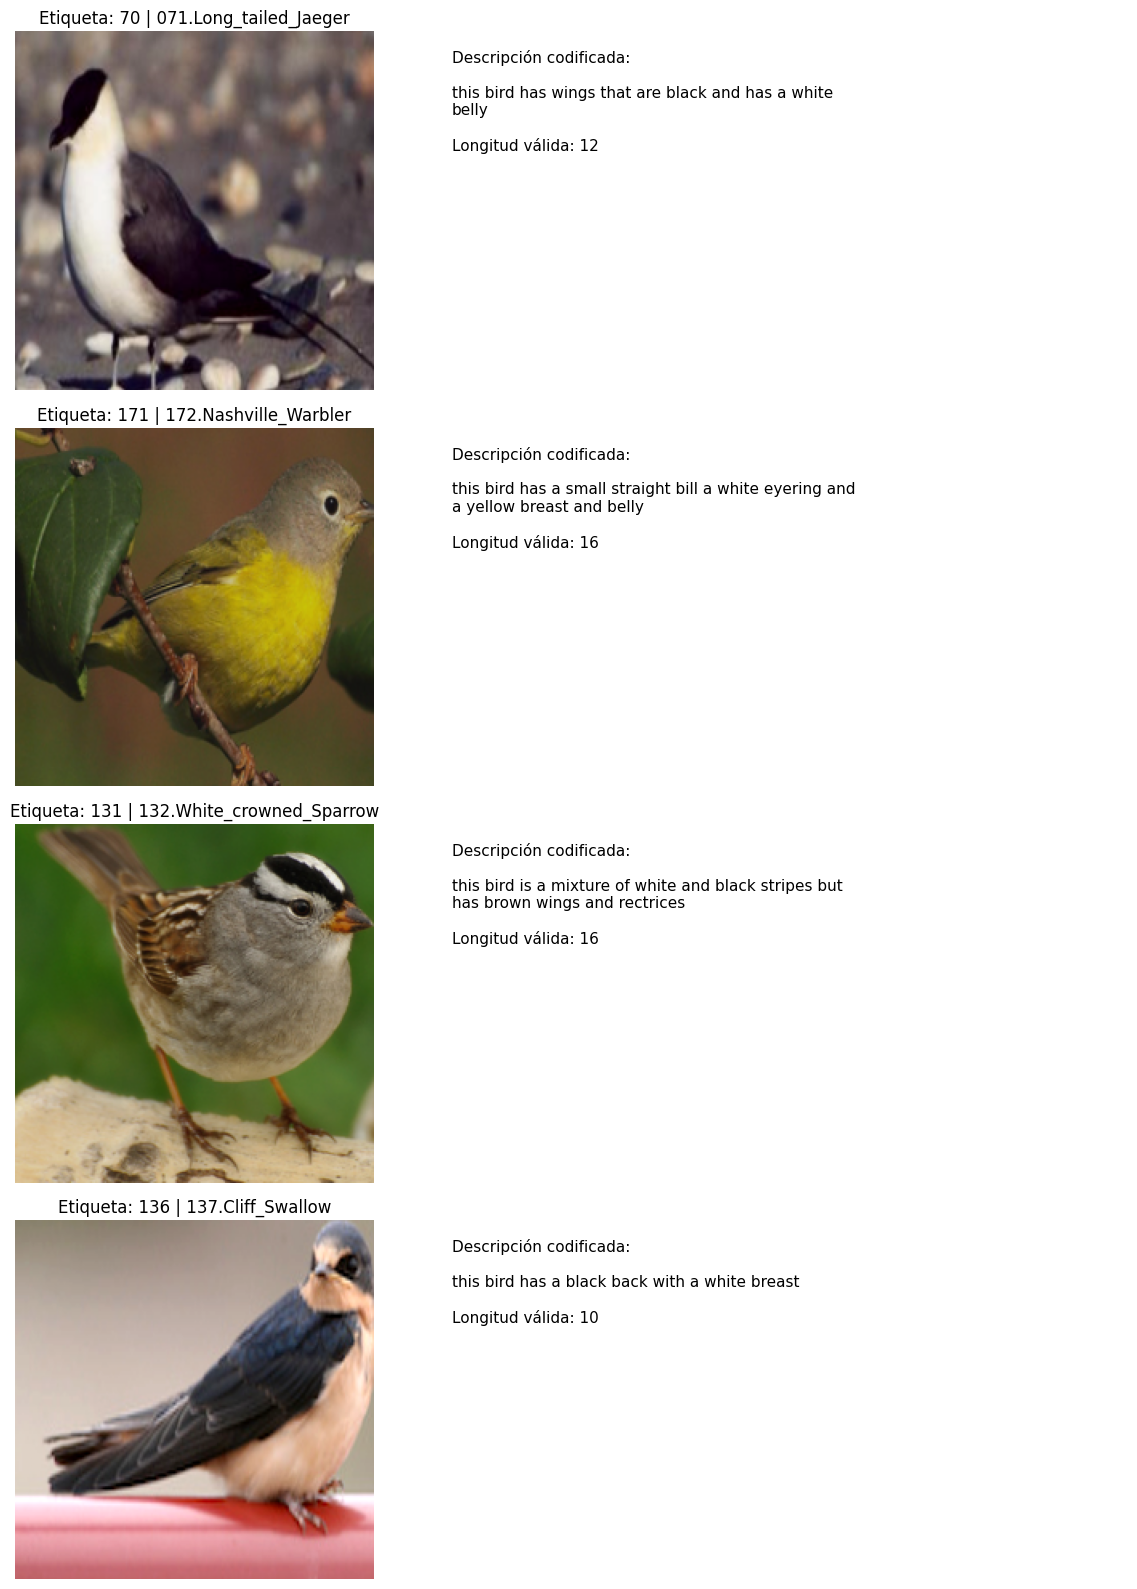

In [104]:
import matplotlib.pyplot as plt
import textwrap

# ------------------------------------------------------------
# 1. RELACIONAR LAS ETIQUETAS CON LOS NOMBRES DE ESPECIE
# ------------------------------------------------------------
# Construimos la correspondencia usando las etiquetas 0...199
# y los nombres registrados en la tabla maestra.
label_to_name = (
    image_table[["label", "class_name"]]
    .drop_duplicates()
    .set_index("label")["class_name"]
    .to_dict()
)


# ------------------------------------------------------------
# 2. PREPARAR LA INVERSIÓN DE LA NORMALIZACIÓN
# ------------------------------------------------------------
# Durante el preprocesamiento:
#   normalizada = (imagen - media) / desviación
#
# Para visualizar:
#   imagen = normalizada * desviación + media
#
# La forma (3, 1, 1) permite operar sobre los tres canales.
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)


# ------------------------------------------------------------
# 3. CREAR UNA FIGURA PARA CUATRO OBSERVACIONES
# ------------------------------------------------------------
n_examples = min(4, batch_labels.shape[0])

fig, axes = plt.subplots(
    n_examples,
    2,
    figsize=(13, 4 * n_examples),
    squeeze=False,
)


# ------------------------------------------------------------
# 4. RECUPERAR Y MOSTRAR CADA OBSERVACIÓN
# ------------------------------------------------------------
for i in range(n_examples):

    # Recuperamos la imagen en CPU sin modificar el lote.
    normalized_image = batch_inputs["image"][i].detach().cpu()

    # Invertimos la normalización y limitamos pequeños
    # desajustes numéricos al rango válido para visualizar.
    display_image = (
        normalized_image * std + mean
    ).clamp(0, 1)

    # Matplotlib espera (alto, ancho, canales).
    display_image = display_image.permute(1, 2, 0).numpy()

    # Recuperamos la especie correspondiente.
    label = int(batch_labels[i].item())
    species = label_to_name[label]

    # Reconstruimos la descripción sin incluir el relleno.
    length = int(batch_inputs["lengths"][i].item())

    token_ids = (
        batch_inputs["input_ids"][i, :length]
        .detach()
        .cpu()
        .tolist()
    )

    caption = " ".join(
        id_to_word[token_id]
        for token_id in token_ids
    )

    # Mostramos la imagen ya recortada y aumentada.
    axes[i, 0].imshow(display_image)
    axes[i, 0].set_title(f"Etiqueta: {label} | {species}")
    axes[i, 0].axis("off")

    # Mostramos el texto que efectivamente recibió el pipeline.
    # Puede contener <unk> o estar truncado a 25 tokens.
    axes[i, 1].text(
        0,
        0.95,
        "Descripción codificada:\n\n"
        + textwrap.fill(caption, width=55)
        + f"\n\nLongitud válida: {length}",
        transform=axes[i, 1].transAxes,
        va="top",
        fontsize=11,
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

Los ejemplos presentados muestran descripciones correctas de las imágenes asociadas. Este muestreo, aunque pequeño nos ayuda a revisar de una manera muy somera que a nivel aleatorio, los datos están correca o incorrectamente relacionados, en este caso, de manera correcta se ha resuelto este emparejamiento.

<a id="pipeline-tensorflow"></a>

# **PIPELINE EN TENSORFLOW**



En esta sección implementamos el pipeline multimodal mediante tf.data. Utilizamos las mismas particiones, etiquetas, descripciones codificadas y características tabulares preparadas para PyTorch. Las imágenes se cargarán desde sus archivos.

La diferencia principal de formato será el orden de los ejes: TensorFlow entregará imágenes con forma (224, 224, 3) por observación y (B, 224, 224, 3) por lote. Las reglas de preprocesamiento serán las mismas, aunque las implementaciones de ambos frameworks pueden producir diferencias numéricas y aumentaciones aleatorias distintas.

## Importar TensorFlow y comprobar los datos de partida.

In [105]:
import tensorflow as tf

# ------------------------------------------------------------
# 1. FIJAR LA SEMILLA DE TENSORFLOW
# ------------------------------------------------------------
# Seguimos la organización del notebook de referencia.
# La semilla facilita reproducir las operaciones aleatorias
# bajo las mismas condiciones de ejecución.
tf.random.set_seed(42)

print("Versión de TensorFlow:", tf.__version__)


# ------------------------------------------------------------
# 2. DEFINIR LA CONFIGURACIÓN DEL PIPELINE
# ------------------------------------------------------------
# Utilizamos el mismo tamaño de lote que en PyTorch
# para facilitar la comparación.
TF_BATCH_SIZE = 32

# AUTOTUNE permitirá que TensorFlow ajuste el paralelismo
# y la precarga cuando construyamos el pipeline.
AUTOTUNE = tf.data.AUTOTUNE


# ------------------------------------------------------------
# 3. COMPROBAR LAS TABLAS DE LA PREPARACIÓN COMÚN
# ------------------------------------------------------------
# No creamos nuevas particiones: verificamos las existentes.
for name, table, expected_size in [
    ("train", train_table, 5_394),
    ("val", val_table, 600),
    ("test", test_table, 5_794),
]:
    assert len(table) == expected_size, (
        f"Tamaño inesperado en {name}."
    )

    assert table["split"].eq(name).all(), (
        f"Hay asignaciones incorrectas en {name}."
    )

    print(f"{name}: {len(table):,} imágenes")


# ------------------------------------------------------------
# 4. COMPROBAR LOS PARÁMETROS COMUNES
# ------------------------------------------------------------
# Reutilizamos el vocabulario, la longitud máxima y el orden
# de las características tabulares, sin volver a ajustarlos.
assert len(tabular_columns) == 318
assert vocab["<pad>"] == 0
assert vocab["<unk>"] == 1

print("\nTamaño del vocabulario:", len(vocab))
print("Longitud máxima del texto:", max_len)
print("Características tabulares:", len(tabular_columns))
print("Tamaño de lote:", TF_BATCH_SIZE)

Versión de TensorFlow: 2.21.0
train: 5,394 imágenes
val: 600 imágenes
test: 5,794 imágenes

Tamaño del vocabulario: 2079
Longitud máxima del texto: 25
Características tabulares: 318
Tamaño de lote: 32


## Construcción de los datasets iniciales para TensorFlow

Convertimos cada partición en un dataset de TensorFlow. Cada elemento contendrá la ruta de la fotografía, su caja delimitadora, las diez descripciones codificadas, sus longitudes, las 318 características tabulares y la etiqueta.

En este paso todavía no abrimos las imágenes ni seleccionamos una descripción. Conservamos las diez alternativas para realizar la selección durante el preprocesamiento.

In [106]:
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# 1. DEFINIR LA CONVERSIÓN DE UNA TABLA A DATASET
# ------------------------------------------------------------
def build_raw_tf_dataset(table):

    # Construimos las rutas completas de las fotografías.
    # Solo guardamos sus nombres; no cargamos los píxeles.
    image_paths = np.asarray(
        [
            str(CUB_DIR / "images" / Path(relative_path))
            for relative_path in table["image_path"]
        ],
        dtype=str,
    )

    # Conservamos el orden de las coordenadas originales:
    # x, y, ancho y alto, expresados en píxeles.
    boxes = table[
        ["bbox_x", "bbox_y", "bbox_w", "bbox_h"]
    ].to_numpy(dtype=np.float32, copy=True)

    # stack reúne los arreglos individuales en uno:
    # (número de imágenes, 10 descripciones, max_len).
    caption_ids = np.stack(
        table["caption_ids"].to_list()
    ).astype(np.int64)

    # Longitudes válidas de las diez descripciones:
    # (número de imágenes, 10).
    caption_lengths = np.stack(
        table["caption_lengths"].to_list()
    ).astype(np.int64)

    # Recuperamos las 318 características en el orden común.
    tabular = table[tabular_columns].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    # Recuperamos las etiquetas enteras de 0 a 199.
    labels = table["label"].to_numpy(
        dtype=np.int64,
        copy=True,
    )

    # Organizamos las entradas de cada observación.
    features = {
        "image_path": image_paths,
        "bbox": boxes,
        "caption_ids": caption_ids,
        "caption_lengths": caption_lengths,
        "tabular": tabular,
    }

    # from_tensor_slices toma una posición de cada arreglo
    # para formar una observación y mantener su correspondencia.
    return tf.data.Dataset.from_tensor_slices(
        (features, labels)
    )


# ------------------------------------------------------------
# 2. CREAR LOS TRES DATASETS INICIALES
# ------------------------------------------------------------
# Reutilizamos exactamente las particiones ya definidas.
tf_train_raw = build_raw_tf_dataset(train_table)
tf_val_raw = build_raw_tf_dataset(val_table)
tf_test_raw = build_raw_tf_dataset(test_table)


# ------------------------------------------------------------
# 3. COMPROBAR EL NÚMERO DE OBSERVACIONES
# ------------------------------------------------------------
for name, dataset, expected_size in [
    ("train", tf_train_raw, 5_394),
    ("val", tf_val_raw, 600),
    ("test", tf_test_raw, 5_794),
]:
    count = int(dataset.cardinality().numpy())
    assert count == expected_size

    print(f"{name}: {count:,} observaciones")


# ------------------------------------------------------------
# 4. INSPECCIONAR UNA OBSERVACIÓN DE ENTRENAMIENTO
# ------------------------------------------------------------
# take(1) selecciona una observación, todavía sin agrupar.
for features, label in tf_train_raw.take(1):

    print("\nRuta de imagen:")
    print(features["image_path"].numpy().decode("utf-8"))

    print("\nEstructura de las entradas:")
    for name, tensor in features.items():
        print(
            f"{name}: forma={tuple(tensor.shape)}, "
            f"tipo={tensor.dtype.name}"
        )

    print("\nEtiqueta:", int(label.numpy()))

train: 5,394 observaciones
val: 600 observaciones
test: 5,794 observaciones

Ruta de imagen:
/content/data/CUB_200_2011/images/001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg

Estructura de las entradas:
image_path: forma=(), tipo=string
bbox: forma=(4,), tipo=float32
caption_ids: forma=(10, 25), tipo=int64
caption_lengths: forma=(10,), tipo=int64
tabular: forma=(318,), tipo=float32

Etiqueta: 0


## Preprocesamiento: Carga de fotos, recorte de caja y aplica transformaciónes.

El preprocesamiento carga la fotografía, recorta la caja delimitadora con margen y aplica las transformaciones correspondientes a la partición. También selecciona una descripción: aleatoria en entrenamiento y siempre la primera en validación y prueba.

Conservamos la interpretación del margen utilizada en PyTorch: añadir el 10 % del ancho y del alto de la caja a cada lado, sin superar los bordes de la fotografía. Las imágenes resultantes tendrán forma (224, 224, 3).

Para brillo y contraste utilizamos factores aleatorios entre 0,8 y 1,2. Los frameworks pueden producir diferencias numéricas por sus implementaciones de decodificación, interpolación y aumentación.

In [107]:
# ------------------------------------------------------------
# 1. DEFINIR LAS CONSTANTES DE NORMALIZACIÓN
# ------------------------------------------------------------
# Definimos constantes propias de TensorFlow para que esta
# sección no dependa de ejecutar la implementación de PyTorch.
TF_MEAN = tf.constant(
    [0.485, 0.456, 0.406],
    dtype=tf.float32,
)

TF_STD = tf.constant(
    [0.229, 0.224, 0.225],
    dtype=tf.float32,
)


# ------------------------------------------------------------
# 2. DEFINIR EL PREPROCESAMIENTO DE UNA OBSERVACIÓN
# ------------------------------------------------------------
def preprocess_tf(features, label, training=False):

    # Leer los bytes y decodificar la fotografía con tres canales.
    image_bytes = tf.io.read_file(features["image_path"])
    image = tf.io.decode_jpeg(image_bytes, channels=3)

    # Obtener las dimensiones originales.
    image_height = tf.shape(image)[0]
    image_width = tf.shape(image)[1]

    # Recuperar la caja: x, y, ancho y alto.
    x, y, w, h = tf.unstack(features["bbox"])

    # --------------------------------------------------------
    # 2A. CALCULAR EL RECORTE CON MARGEN
    # --------------------------------------------------------
    margin = tf.constant(0.10, dtype=tf.float32)

    left = tf.maximum(
        0,
        tf.cast(tf.floor(x - margin * w), tf.int32),
    )
    top = tf.maximum(
        0,
        tf.cast(tf.floor(y - margin * h), tf.int32),
    )
    right = tf.minimum(
        image_width,
        tf.cast(tf.math.ceil(x + w + margin * w), tf.int32),
    )
    bottom = tf.minimum(
        image_height,
        tf.cast(tf.math.ceil(y + h + margin * h), tf.int32),
    )

    # Detener el proceso si el recorte no tiene área positiva.
    tf.debugging.assert_greater(right, left)
    tf.debugging.assert_greater(bottom, top)

    image = tf.image.crop_to_bounding_box(
        image,
        offset_height=top,
        offset_width=left,
        target_height=bottom - top,
        target_width=right - left,
    )

    # --------------------------------------------------------
    # 2B. REDIMENSIONAR Y TRANSFORMAR LA IMAGEN
    # --------------------------------------------------------
    # Convertir de uint8 [0, 255] a float32 [0, 1]
    # antes del redimensionamiento.
    image = tf.image.convert_image_dtype(image, tf.float32)

    image = tf.image.resize(
        image,
        size=[256, 256],
        method="bilinear",
        antialias=True,
    )

    if training:
        # Recorte y volteo aleatorios, solo en entrenamiento.
        image = tf.image.random_crop(image, size=[224, 224, 3])
        image = tf.image.random_flip_left_right(image)

        # Brillo multiplicativo: factor entre 0.8 y 1.2.
        # Evitamos confundirlo con random_brightness,
        # que utiliza un cambio aditivo.
        brightness_factor = tf.random.uniform([], 0.8, 1.2)
        image = tf.clip_by_value(
            image * brightness_factor, 0.0, 1.0
        )

        # Contraste: factor entre 0.8 y 1.2.
        image = tf.image.random_contrast(
            image,
            lower=0.8,
            upper=1.2,
        )
        image = tf.clip_by_value(image, 0.0, 1.0)

    else:
        # De 256 a 224 quedan 32 píxeles de diferencia:
        # retiramos 16 por cada lado para centrar el recorte.
        image = tf.image.crop_to_bounding_box(
            image,
            offset_height=16,
            offset_width=16,
            target_height=224,
            target_width=224,
        )

    # Normalizar los tres canales con las constantes de ImageNet.
    image = (image - TF_MEAN) / TF_STD
    image = tf.ensure_shape(image, [224, 224, 3])

    # --------------------------------------------------------
    # 2C. SELECCIONAR UNA DESCRIPCIÓN
    # --------------------------------------------------------
    if training:
        caption_idx = tf.random.uniform(
            shape=[],
            minval=0,
            maxval=tf.shape(features["caption_ids"])[0],
            dtype=tf.int32,
        )
    else:
        caption_idx = tf.constant(0, dtype=tf.int32)

    input_ids = tf.gather(
        features["caption_ids"], caption_idx
    )
    length = tf.gather(
        features["caption_lengths"], caption_idx
    )

    # --------------------------------------------------------
    # 2D. ENTREGAR LAS ENTRADAS Y LA ETIQUETA
    # --------------------------------------------------------
    # Las variables tabulares ya se prepararon y escalaron
    # en la sección común; aquí no reajustamos el escalador.
    inputs = {
        "image": image,
        "input_ids": input_ids,
        "lengths": length,
        "tabular": features["tabular"],
    }

    return inputs, label


print("Función de preprocesamiento de TensorFlow definida.")

Función de preprocesamiento de TensorFlow definida.


##Preprocesamiento: Agrupación de los datos por lotes (batches).

Construimos los pipelines de TensorFlow a partir de los datasets iniciales. **cache()** conserva las rutas y los datos numéricos, sin almacenar las imágenes transformadas. En entrenamiento, **shuffle()** mezcla las observaciones y **map()** aplica el preprocesamiento con aumentaciones y selección aleatoria de descripción. En validación y prueba, el preprocesamiento es determinista.

Finalmente, **batch()** agrupa hasta 32 observaciones y **prefetch()** permite preparar próximos lotes mientras se consume el actual. Conservamos el último lote incompleto.

In [108]:
# ------------------------------------------------------------
# 1. DEFINIR LA CONSTRUCCIÓN DEL PIPELINE
# ------------------------------------------------------------
def build_tf_pipeline(raw_dataset, training=False):

    # Guardamos en memoria las entradas originales:
    # rutas, cajas, textos codificados y variables tabulares.
    # Las fotografías todavía permanecen en disco.
    dataset = raw_dataset.cache()

    # Mezclamos únicamente las observaciones de entrenamiento.
    # El buffer abarca toda esta partición.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(train_table),
            seed=42,
            reshuffle_each_iteration=True,
        )

    # Aplicamos el preprocesamiento a cada observación.
    # AUTOTUNE permite procesar varias en paralelo.
    # deterministic=True conserva el orden de entrega de map;
    # no elimina las aumentaciones aleatorias de entrenamiento.
    dataset = dataset.map(
        lambda features, label: preprocess_tf(
            features,
            label,
            training=training,
        ),
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    # Agrupamos las observaciones sin descartar las últimas.
    dataset = dataset.batch(
        TF_BATCH_SIZE,
        drop_remainder=False,
    )

    # Preparamos próximos lotes de manera anticipada.
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# ------------------------------------------------------------
# 2. CREAR LOS TRES PIPELINES
# ------------------------------------------------------------
tf_train_ds = build_tf_pipeline(
    tf_train_raw,
    training=True,
)

tf_val_ds = build_tf_pipeline(
    tf_val_raw,
    training=False,
)

tf_test_ds = build_tf_pipeline(
    tf_test_raw,
    training=False,
)


# ------------------------------------------------------------
# 3. INSPECCIONAR UN LOTE DE ENTRENAMIENTO
# ------------------------------------------------------------
# Usamos nombres distintos de los de PyTorch para conservar
# ambos lotes disponibles en el notebook.
tf_batch_inputs, tf_batch_labels = next(iter(tf_train_ds))

for name, tensor in tf_batch_inputs.items():
    print(
        f"{name}: forma={tuple(tensor.shape)}, "
        f"tipo={tensor.dtype.name}"
    )

print(
    f"labels: forma={tuple(tf_batch_labels.shape)}, "
    f"tipo={tf_batch_labels.dtype.name}"
)


# ------------------------------------------------------------
# 4. VERIFICAR LAS DIMENSIONES
# ------------------------------------------------------------
assert tuple(tf_batch_inputs["image"].shape) == (
    TF_BATCH_SIZE, 224, 224, 3
)
assert tuple(tf_batch_inputs["input_ids"].shape) == (
    TF_BATCH_SIZE, max_len
)
assert tuple(tf_batch_inputs["lengths"].shape) == (
    TF_BATCH_SIZE,
)
assert tuple(tf_batch_inputs["tabular"].shape) == (
    TF_BATCH_SIZE, 318
)
assert tuple(tf_batch_labels.shape) == (TF_BATCH_SIZE,)

print("\nDimensiones del lote verificadas.")


# ------------------------------------------------------------
# 5. MOSTRAR EL NÚMERO DE LOTES
# ------------------------------------------------------------
for name, dataset in [
    ("entrenamiento", tf_train_ds),
    ("validación", tf_val_ds),
    ("prueba", tf_test_ds),
]:
    print(
        f"Lotes de {name}:",
        int(dataset.cardinality().numpy()),
    )

image: forma=(32, 224, 224, 3), tipo=float32
input_ids: forma=(32, 25), tipo=int64
lengths: forma=(32,), tipo=int64
tabular: forma=(32, 318), tipo=float32
labels: forma=(32,), tipo=int64

Dimensiones del lote verificadas.
Lotes de entrenamiento: 169
Lotes de validación: 19
Lotes de prueba: 182


## Verificación de valores de un ejemplo




Después de inspeccionar las dimensiones y los tipos de datos, verificamos la consistencia numérica del lote multimodal. Comprobamos que las imágenes y variables tabulares contengan valores finitos, que los atributos binarios conserven sus valores y que las etiquetas e identificadores de palabras estén dentro de los rangos permitidos. También verificamos la correspondencia entre las longitudes textuales y las posiciones de relleno. Estas comprobaciones se limitan al lote inspeccionado.

In [109]:
# ------------------------------------------------------------
# 1. VERIFICAR LOS VALORES DE LAS IMÁGENES
# ------------------------------------------------------------
images_tf = tf_batch_inputs["image"]

# Detiene la ejecución si encuentra NaN o infinitos.
tf.debugging.assert_all_finite(
    images_tf,
    "Las imágenes contienen NaN o infinitos.",
)

# Los valores normalizados no están limitados a [0, 1].
print(
    "✓ Imágenes: valores finitos. "
    f"Rango observado: [{tf.reduce_min(images_tf).numpy():.3f}, "
    f"{tf.reduce_max(images_tf).numpy():.3f}]"
)


# ------------------------------------------------------------
# 2. VERIFICAR LAS CARACTERÍSTICAS TABULARES
# ------------------------------------------------------------
tabular_tf = tf_batch_inputs["tabular"]

tf.debugging.assert_all_finite(
    tabular_tf,
    "Las características tabulares contienen NaN o infinitos.",
)

# Las primeras 312 columnas son los atributos binarios.
binary_tf = tabular_tf[:, :312]

tf.debugging.assert_equal(
    tf.reduce_all(
        tf.logical_or(binary_tf == 0, binary_tf == 1)
    ),
    True,
    message="Hay atributos binarios distintos de 0 y 1.",
)

print("✓ Tabular: valores finitos y atributos binarios válidos.")


# ------------------------------------------------------------
# 3. VERIFICAR LAS ETIQUETAS
# ------------------------------------------------------------
# Usamos constantes del mismo tipo entero que las etiquetas.
tf.debugging.assert_greater_equal(
    tf_batch_labels,
    tf.constant(0, dtype=tf_batch_labels.dtype),
)

tf.debugging.assert_less(
    tf_batch_labels,
    tf.constant(200, dtype=tf_batch_labels.dtype),
)

print("✓ Etiquetas: todas están entre 0 y 199.")


# ------------------------------------------------------------
# 4. VERIFICAR LOS IDENTIFICADORES TEXTUALES
# ------------------------------------------------------------
ids_tf = tf_batch_inputs["input_ids"]

tf.debugging.assert_greater_equal(
    ids_tf,
    tf.constant(0, dtype=ids_tf.dtype),
)

tf.debugging.assert_less(
    ids_tf,
    tf.constant(len(vocab), dtype=ids_tf.dtype),
)

print("✓ Texto: todos los IDs pertenecen al vocabulario.")


# ------------------------------------------------------------
# 5. VERIFICAR LAS LONGITUDES VÁLIDAS
# ------------------------------------------------------------
lengths_tf = tf_batch_inputs["lengths"]

tf.debugging.assert_greater_equal(
    lengths_tf,
    tf.constant(1, dtype=lengths_tf.dtype),
)

tf.debugging.assert_less_equal(
    lengths_tf,
    tf.constant(max_len, dtype=lengths_tf.dtype),
)


# ------------------------------------------------------------
# 6. VERIFICAR EL RELLENO
# ------------------------------------------------------------
# sequence_mask marca con True las posiciones válidas
# y con False las posiciones que deben contener padding.
valid_mask_tf = tf.sequence_mask(
    lengths_tf,
    maxlen=max_len,
)

valid_ids_tf = tf.boolean_mask(ids_tf, valid_mask_tf)
padding_ids_tf = tf.boolean_mask(
    ids_tf,
    tf.logical_not(valid_mask_tf),
)

# No debe aparecer <pad> dentro de las posiciones válidas.
tf.debugging.assert_equal(
    tf.reduce_all(valid_ids_tf != vocab["<pad>"]),
    True,
    message="Hay padding dentro del texto válido.",
)

# Después de la longitud válida solo debe aparecer <pad>.
tf.debugging.assert_equal(
    tf.reduce_all(padding_ids_tf == vocab["<pad>"]),
    True,
    message="Hay valores distintos de padding al final.",
)

print("✓ Longitudes y relleno: consistentes.")


# ------------------------------------------------------------
# 7. RECONSTRUIR UNA DESCRIPCIÓN DEL LOTE
# ------------------------------------------------------------
first_length_tf = int(lengths_tf[0].numpy())

decoded_tf = [
    id_to_word[int(index)]
    for index in ids_tf[0, :first_length_tf].numpy()
]

print("\nPrimera descripción codificada:")
print(" ".join(decoded_tf))
print("Longitud válida:", first_length_tf)
print("Posiciones de relleno:", max_len - first_length_tf)

print("\n✓ Todas las verificaciones del lote se completaron.")

✓ Imágenes: valores finitos. Rango observado: [-2.118, 2.640]
✓ Tabular: valores finitos y atributos binarios válidos.
✓ Etiquetas: todas están entre 0 y 199.
✓ Texto: todos los IDs pertenecen al vocabulario.
✓ Longitudes y relleno: consistentes.

Primera descripción codificada:
a small black and brown bird with light eyes and black feet
Longitud válida: 12
Posiciones de relleno: 13

✓ Todas las verificaciones del lote se completaron.


El lote inspeccionado presenta consistencia estructural y numérica: las imágenes y características tabulares contienen valores finitos, los atributos conservan su codificación binaria y las etiquetas e identificadores textuales están dentro de los rangos previstos. Las longitudes válidas coinciden con la ubicación del relleno.

Estos resultados verifican el lote revisado; todavía no constituyen una evaluación de clasificación ni una comprobación de todas las observaciones.

## Visualización de imágenes del lote junto con sus especies y descripciones

Visualizamos cuatro observaciones del lote de entrenamiento para inspeccionar la compatibilidad entre las fotografías, las etiquetas de especie y las descripciones seleccionadas.

Para mostrar las imágenes, invertimos la normalización de ImageNet sin modificar el lote original. En TensorFlow, los canales ya están en el último eje, por lo que no necesitamos reorganizarlos para Matplotlib.

El texto mostrado corresponde a la secuencia codificada: puede estar truncado o contener <unk>. Además, las aumentaciones y el recorte aleatorio pueden modificar la apariencia u ocultar características mencionadas en la descripción original. Esta inspección complementa las verificaciones numéricas, pero no demuestra la correspondencia de todo el dataset.

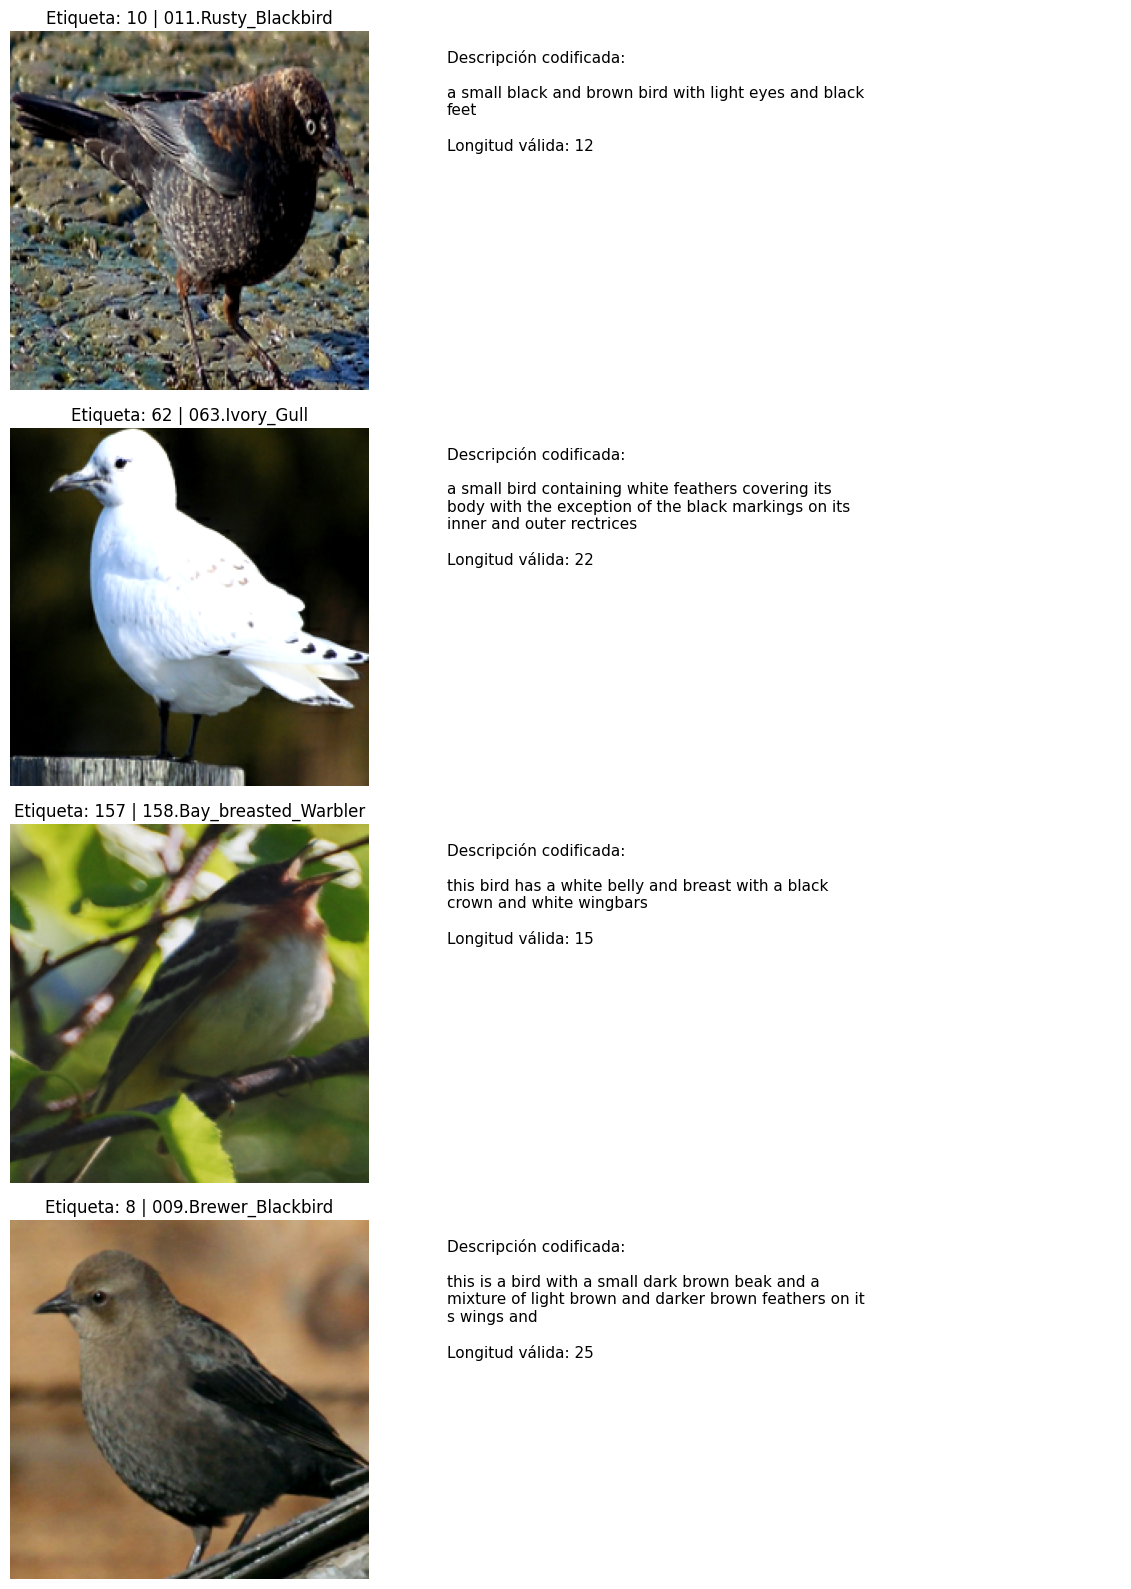

In [110]:
import matplotlib.pyplot as plt
import textwrap

# ------------------------------------------------------------
# 1. RELACIONAR ETIQUETAS CON NOMBRES DE ESPECIE
# ------------------------------------------------------------
# Definimos esta correspondencia desde la preparación común,
# sin depender de ejecutar la visualización de PyTorch.
tf_label_to_name = (
    image_table[["label", "class_name"]]
    .drop_duplicates()
    .set_index("label")["class_name"]
    .to_dict()
)


# ------------------------------------------------------------
# 2. PREPARAR LA FIGURA
# ------------------------------------------------------------
# Mostraremos hasta cuatro observaciones del lote actual.
n_examples_tf = min(
    4,
    int(tf.shape(tf_batch_labels)[0].numpy()),
)

fig, axes = plt.subplots(
    n_examples_tf,
    2,
    figsize=(13, 4 * n_examples_tf),
    squeeze=False,
)


# ------------------------------------------------------------
# 3. RECUPERAR CADA IMAGEN PARA VISUALIZARLA
# ------------------------------------------------------------
for i in range(n_examples_tf):

    # Invertimos: normalizada = (imagen - media) / desviación.
    # Esta operación crea un tensor nuevo; no modifica el lote.
    display_image_tf = (
        tf_batch_inputs["image"][i] * TF_STD + TF_MEAN
    )

    # Limitamos los valores al rango de visualización [0, 1].
    display_image_tf = tf.clip_by_value(
        display_image_tf,
        0.0,
        1.0,
    ).numpy()

    # Recuperamos la etiqueta y el nombre de la especie.
    label_tf = int(tf_batch_labels[i].numpy())
    species_tf = tf_label_to_name[label_tf]

    # --------------------------------------------------------
    # 4. RECONSTRUIR LA DESCRIPCIÓN SIN EL RELLENO
    # --------------------------------------------------------
    length_tf = int(
        tf_batch_inputs["lengths"][i].numpy()
    )

    token_ids_tf = tf_batch_inputs[
        "input_ids"
    ][i, :length_tf].numpy()

    caption_tf = " ".join(
        id_to_word[int(token_id)]
        for token_id in token_ids_tf
    )

    # --------------------------------------------------------
    # 5. MOSTRAR IMAGEN, ESPECIE Y TEXTO
    # --------------------------------------------------------
    # TensorFlow ya utiliza (alto, ancho, canales).
    axes[i, 0].imshow(display_image_tf)
    axes[i, 0].set_title(
        f"Etiqueta: {label_tf} | {species_tf}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].text(
        0,
        0.95,
        "Descripción codificada:\n\n"
        + textwrap.fill(caption_tf, width=55)
        + f"\n\nLongitud válida: {length_tf}",
        transform=axes[i, 1].transAxes,
        va="top",
        fontsize=11,
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## Verificación final de ambos pipelines

Verificamos que ambos pipelines procesen todas las observaciones y entreguen las dimensiones, tipos y valores esperados, incluidos los últimos lotes incompletos. Para validación y prueba, contrastamos etiquetas, textos y atributos con las tablas originales y entre frameworks, y comprobamos la estabilidad de lecturas repetidas.

Esta revisión no entrena ningún modelo ni utiliza los resultados de prueba para ajustar parámetros. Las imágenes de ambos frameworks deben cumplir el mismo formato conceptual, aunque no se exige igualdad píxel a píxel por las diferencias de procesamiento.

In [111]:
import numpy as np
import pandas as pd
import torch
import tensorflow as tf
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. DEFINIR UNA VERIFICACIÓN COMÚN PARA CADA LOTE
# ------------------------------------------------------------
# Recibimos arreglos NumPy para aplicar las mismas reglas
# a las salidas de PyTorch y TensorFlow.
def check_batch_arrays(images, ids, lengths, tabular, labels, framework):
    batch_size = len(labels)

    # La ubicación del canal de color depende del framework.
    expected_image_shape = (
        (batch_size, 3, 224, 224)
        if framework == "PyTorch"
        else (batch_size, 224, 224, 3)
    )

    assert images.shape == expected_image_shape
    assert ids.shape == (batch_size, max_len)
    assert lengths.shape == (batch_size,)
    assert tabular.shape == (batch_size, 318)
    assert labels.shape == (batch_size,)

    # Verificar los tipos solicitados.
    assert images.dtype == np.float32
    assert tabular.dtype == np.float32
    assert ids.dtype == np.int64
    assert lengths.dtype == np.int64
    assert labels.dtype == np.int64

    # Verificar valores numéricos y rangos.
    assert np.isfinite(images).all()
    assert np.isfinite(tabular).all()
    assert np.isin(tabular[:, :312], [0, 1]).all()
    assert ((labels >= 0) & (labels < 200)).all()
    assert ((ids >= 0) & (ids < len(vocab))).all()
    assert ((lengths >= 1) & (lengths <= max_len)).all()

    # Verificar que el relleno aparezca únicamente al final.
    valid_mask = np.arange(max_len)[None, :] < lengths[:, None]

    assert (ids[valid_mask] != vocab["<pad>"]).all()
    assert (ids[~valid_mask] == vocab["<pad>"]).all()


# ------------------------------------------------------------
# 2. RECORRER COMPLETOS LOS SEIS PIPELINES
# ------------------------------------------------------------
# Conservamos solo las salidas no visuales de val/test
# para compararlas después, sin almacenar todas las imágenes.
collected = {}
summary_rows = []

pipeline_pairs = [
    ("train", train_loader, tf_train_ds, train_table),
    ("val", val_loader, tf_val_ds, val_table),
    ("test", test_loader, tf_test_ds, test_table),
]

for split, torch_loader, tf_dataset, table in pipeline_pairs:
    for framework, loader in [
        ("PyTorch", torch_loader),
        ("TensorFlow", tf_dataset),
    ]:
        count = 0
        batches = 0
        last_batch_size = 0

        saved = {
            "input_ids": [],
            "lengths": [],
            "tabular": [],
            "labels": [],
        }

        total_batches = (
            len(loader)
            if framework == "PyTorch"
            else int(loader.cardinality().numpy())
        )

        for inputs, labels in tqdm(
            loader,
            total=total_batches,
            desc=f"{framework} / {split}",
        ):
            # Convertir las salidas sin modificar los pipelines.
            if framework == "PyTorch":
                arrays = {
                    name: tensor.detach().cpu().numpy()
                    for name, tensor in inputs.items()
                }
                labels_array = labels.detach().cpu().numpy()
            else:
                arrays = {
                    name: tensor.numpy()
                    for name, tensor in inputs.items()
                }
                labels_array = labels.numpy()

            check_batch_arrays(
                arrays["image"],
                arrays["input_ids"],
                arrays["lengths"],
                arrays["tabular"],
                labels_array,
                framework,
            )

            last_batch_size = len(labels_array)
            count += last_batch_size
            batches += 1

            # Val/test no mezclan el orden, por lo que sus
            # salidas pueden compararse fila a fila.
            if split != "train":
                for name in ["input_ids", "lengths", "tabular"]:
                    saved[name].append(arrays[name])

                saved["labels"].append(labels_array)

        assert count == len(table), (
            f"{framework}/{split}: número incorrecto de ejemplos."
        )

        if split != "train":
            collected[(framework, split)] = {
                name: np.concatenate(parts, axis=0)
                for name, parts in saved.items()
            }

        summary_rows.append({
            "framework": framework,
            "split": split,
            "observaciones": count,
            "lotes": batches,
            "ultimo_lote": last_batch_size,
        })


# ------------------------------------------------------------
# 3. CONTRASTAR VAL/TEST CON LAS TABLAS Y ENTRE FRAMEWORKS
# ------------------------------------------------------------
for split, table in [
    ("val", val_table),
    ("test", test_table),
]:
    # El taller exige seleccionar la primera descripción.
    expected = {
        "input_ids": np.stack([
            captions[0] for captions in table["caption_ids"]
        ]),
        "lengths": np.asarray([
            lengths[0] for lengths in table["caption_lengths"]
        ], dtype=np.int64),
        "tabular": table[tabular_columns].to_numpy(
            dtype=np.float32
        ),
        "labels": table["label"].to_numpy(dtype=np.int64),
    }

    for name, expected_values in expected.items():
        torch_values = collected[("PyTorch", split)][name]
        tf_values = collected[("TensorFlow", split)][name]

        # Coincidencia con la preparación común.
        np.testing.assert_array_equal(torch_values, expected_values)
        np.testing.assert_array_equal(tf_values, expected_values)

        # Coincidencia entre ambos frameworks.
        np.testing.assert_array_equal(torch_values, tf_values)

    print(
        f"✓ {split}: etiquetas, primera descripción, longitudes "
        "y atributos coinciden con las tablas y entre frameworks."
    )


# ------------------------------------------------------------
# 4. COMPROBAR LECTURAS REPETIDAS EN VALIDACIÓN Y PRUEBA
# ------------------------------------------------------------
# Revisamos el primer lote de cada partición.
# Incluimos las imágenes para comprobar su estabilidad.
for split, torch_loader, tf_dataset in [
    ("val", val_loader, tf_val_ds),
    ("test", test_loader, tf_test_ds),
]:
    first_inputs, first_labels = next(iter(torch_loader))
    second_inputs, second_labels = next(iter(torch_loader))

    assert torch.equal(first_labels, second_labels)
    for name in first_inputs:
        assert torch.equal(first_inputs[name], second_inputs[name]), (
            f"PyTorch/{split}: cambió el campo {name}."
        )

    first_inputs_tf, first_labels_tf = next(iter(tf_dataset))
    second_inputs_tf, second_labels_tf = next(iter(tf_dataset))

    np.testing.assert_array_equal(
        first_labels_tf.numpy(),
        second_labels_tf.numpy(),
    )

    for name in first_inputs_tf:
        np.testing.assert_array_equal(
            first_inputs_tf[name].numpy(),
            second_inputs_tf[name].numpy(),
        )

    print(f"✓ {split}: primer lote estable en lecturas repetidas.")


# ------------------------------------------------------------
# 5. MOSTRAR EL RESUMEN FINAL
# ------------------------------------------------------------
display(pd.DataFrame(summary_rows))

print("\n✓ Verificación final completada sin errores.")

PyTorch / train:   0%|          | 0/169 [00:00<?, ?it/s]

TensorFlow / train:   0%|          | 0/169 [00:00<?, ?it/s]

PyTorch / val:   0%|          | 0/19 [00:00<?, ?it/s]

TensorFlow / val:   0%|          | 0/19 [00:00<?, ?it/s]

PyTorch / test:   0%|          | 0/182 [00:00<?, ?it/s]

TensorFlow / test:   0%|          | 0/182 [00:00<?, ?it/s]

✓ val: etiquetas, primera descripción, longitudes y atributos coinciden con las tablas y entre frameworks.
✓ test: etiquetas, primera descripción, longitudes y atributos coinciden con las tablas y entre frameworks.
✓ val: primer lote estable en lecturas repetidas.
✓ test: primer lote estable en lecturas repetidas.


,framework,split,observaciones,lotes,ultimo_lote
0,PyTorch,train,5394,169,18
1,TensorFlow,train,5394,169,18
2,PyTorch,val,600,19,24
3,TensorFlow,val,600,19,24
4,PyTorch,test,5794,182,2
5,TensorFlow,test,5794,182,2



✓ Verificación final completada sin errores.


La verificación completa confirmó que los pipelines de PyTorch y TensorFlow procesan las 5.394 observaciones de entrenamiento, 600 de validación y 5.794 de prueba sin errores, conservando los últimos lotes incompletos. Todos los lotes cumplieron las comprobaciones de dimensiones, tipos, valores finitos, atributos binarios, rangos de etiquetas y consistencia del relleno textual.

En validación y prueba, las etiquetas, descripciones seleccionadas, longitudes y características tabulares coincidieron exactamente con la preparación común y entre ambos frameworks. También se comprobó la estabilidad del primer lote de cada una de estas particiones mediante lecturas repetidas.

Los resultados respaldan que ambos pipelines están preparados para entregar entradas a una futura red de clasificación. No se entrenó ningún modelo ni se evaluó exactitud predictiva. Tampoco se exigió igualdad píxel a píxel entre frameworks, debido a las diferencias de procesamiento de imágenes.

##Guardado de datos obtenidos (np.savez_compressed())

Guardamos los datos preparados de cada partición en formato NumPy comprimido. Conservamos las diez descripciones por imagen, sus longitudes, las características tabulares, las etiquetas y las cajas delimitadoras. También guardamos el vocabulario, la configuración y las estadísticas del escalador. No almacenamos imágenes aumentadas, porque estas deben generarse durante el entrenamiento.

In [112]:
from pathlib import Path
import json
import numpy as np

# ------------------------------------------------------------
# 1. ELEGIR UNA UBICACIÓN PERSISTENTE
# ------------------------------------------------------------
# Montamos Google Drive para conservar los archivos
# aunque termine la sesión de Colab.
from google.colab import drive
drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/Deep_Learning_I/CUB_preparado"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. GUARDAR LOS ARREGLOS DE CADA PARTICIÓN
# ------------------------------------------------------------
for name, table in [
    ("train", train_table),
    ("val", val_table),
    ("test", test_table),
]:
    # Cada argumento se convierte en un arreglo con nombre.
    # Usamos rutas relativas para poder cambiar la ubicación
    # de las fotografías en futuras sesiones.
    np.savez_compressed(
        SAVE_DIR / f"{name}.npz",

        image_ids=table["image_id"].to_numpy(dtype=np.int64),

        image_paths=np.asarray(
            table["image_path"].tolist(),
            dtype=str,
        ),

        # Cajas originales: x, y, ancho y alto en píxeles.
        boxes=table[
            ["bbox_x", "bbox_y", "bbox_w", "bbox_h"]
        ].to_numpy(dtype=np.float32),

        # Forma: (número de imágenes, 10, max_len).
        caption_ids=np.stack(
            table["caption_ids"].tolist()
        ).astype(np.int64),

        # Forma: (número de imágenes, 10).
        caption_lengths=np.stack(
            table["caption_lengths"].tolist()
        ).astype(np.int64),

        # 312 atributos binarios + 6 variables estandarizadas.
        tabular=table[tabular_columns].to_numpy(
            dtype=np.float32
        ),

        labels=table["label"].to_numpy(dtype=np.int64),
    )

    print(f"Guardado: {name}.npz")


# ------------------------------------------------------------
# 3. GUARDAR VOCABULARIO Y CONFIGURACIÓN
# ------------------------------------------------------------
# El vocabulario es indispensable: cada ID debe conservar
# exactamente el significado asignado durante la preparación.
metadata = {
    "vocab": vocab,
    "max_len": int(max_len),
    "tabular_columns": tabular_columns,
    "geometry_columns": geometry_columns,
    "class_names": {
        str(int(row.label)): row.class_name
        for row in image_table[
            ["label", "class_name"]
        ].drop_duplicates().itertuples(index=False)
    },
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],
    "bbox_margin_per_side": 0.10,
    "seed": 42,
}

(SAVE_DIR / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 4. GUARDAR LAS ESTADÍSTICAS DEL ESCALADOR
# ------------------------------------------------------------
# Permiten aplicar la misma estandarización a nuevos datos:
# geometría_escalada = (geometría - mean) / scale.
# Las variables tabulares guardadas arriba YA están escaladas.
np.savez_compressed(
    SAVE_DIR / "geometry_scaler.npz",
    mean=geometry_scaler.mean_,
    scale=geometry_scaler.scale_,
    var=geometry_scaler.var_,
)


# ------------------------------------------------------------
# 5. VERIFICAR UN ARCHIVO GUARDADO
# ------------------------------------------------------------
# No utilizamos arreglos de objetos ni necesitamos pickle.
with np.load(
    SAVE_DIR / "train.npz",
    allow_pickle=False,
) as saved:
    for key in saved.files:
        print(
            f"{key}: forma={saved[key].shape}, "
            f"tipo={saved[key].dtype}"
        )

    # Comprobamos que las características guardadas coincidan.
    np.testing.assert_array_equal(
        saved["tabular"],
        train_table[tabular_columns].to_numpy(dtype=np.float32),
    )

print("\nGuardado y comprobación completados.")
print("Ubicación:", SAVE_DIR)

Mounted at /content/drive
Guardado: train.npz
Guardado: val.npz
Guardado: test.npz
image_ids: forma=(5394,), tipo=int64
image_paths: forma=(5394,), tipo=<U81
boxes: forma=(5394, 4), tipo=float32
caption_ids: forma=(5394, 10, 25), tipo=int64
caption_lengths: forma=(5394, 10), tipo=int64
tabular: forma=(5394, 318), tipo=float32
labels: forma=(5394,), tipo=int64

Guardado y comprobación completados.
Ubicación: /content/drive/MyDrive/Deep_Learning_I/CUB_preparado


# **Referencias**

Karpathy, A., & Fei-Fei, L. (2015). Deep visual-semantic alignments for generating image descriptions. En Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 3128–3137). https://www.cv-foundation.org/openaccess/content_cvpr_2015/html/Karpathy_Deep_Visual-Semantic_Alignments_2015_CVPR_paper.html

Kiros, R., Salakhutdinov, R., & Zemel, R. (2014). Multimodal neural language models. En E. P. Xing & T. Jebara (Eds.), Proceedings of the 31st International Conference on Machine Learning (Vol. 32, núm. 2, pp. 595–603). PMLR. https://proceedings.mlr.press/v32/kiros14.html

Reed, S., Akata, Z., Lee, H., & Schiele, B. (2016). Learning deep representations of fine-grained visual descriptions. En Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 49–58). https://openaccess.thecvf.com/content_cvpr_2016/html/Reed_Learning_Deep_Representations_CVPR_2016_paper.html

Van Horn, G., Mac Aodha, O., Song, Y., Cui, Y., Sun, C., Shepard, A., Adam, H., Perona, P., & Belongie, S. (2018). The iNaturalist species classification and detection dataset. En Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 8769–8778). https://doi.org/10.1109/CVPR.2018.00914

Wah, C., Branson, S., Welinder, P., Perona, P., & Belongie, S. (2011). The Caltech-UCSD Birds-200-2011 dataset (Informe técnico CNS-TR-2011-001). California Institute of Technology. https://authors.library.caltech.edu/records/cvm3y-5hh21